# Proyecto completo de Machine Learning: OpenPowerlifting

**Autor:** Daniel Meléndez Loreto  
**Máster de FP en Inteligencia Artificial y Big Data (CPIFP Alan Turing)**  
**Fecha de entrega:** miércoles 25 de noviembre de 2026  
**Vídeo explicativo (YouTube):** https://youtu.be/gDZUEGEjIj8

---
**Presentación del proyecto**

El powerlifting es un deporte de fuerza en el que cada persona hace tres levantamientos: sentadilla, press de banca y peso muerto. En cada uno cuenta su mejor intento, y la suma de los tres da el **total** (`TotalKg`).

Este proyecto intenta responder a una pregunta: **¿puedo predecir el total que va a levantar una persona usando solo datos que se conocen antes de competir?** Por ejemplo, su sexo, su edad, su peso corporal, la equipación que usa, la federación o el país.

Para ello uso OpenPowerlifting, un dataset público con unas cuatro millones de filas de resultados reales de competiciones y 42 columnas.

## 1. Obtención de datos

**Fuente:** OpenPowerlifting (https://www.openpowerlifting.org), un archivo público de resultados históricos de competiciones de powerlifting, a partir de los resultados que proporcionan las federaciones.

**Fichero:** descarga masiva de CSV (`openpowerlifting-latest.zip`), con el CSV del 7 de noviembre de 2026, revisión `f93a530c`. Tiene 4.063.068 filas y 42 columnas.

**Descripción de las columnas:** fichero `README.txt` incluido en la misma descarga.

**Licencia:** dominio público (según el `LICENSE.txt` incluido). La atribución no es obligatoria, pero se recomienda.

**Atribución:** este trabajo usa datos del proyecto OpenPowerlifting, https://www.openpowerlifting.org. Se puede descargar una copia de los datos en https://gitlab.com/openpowerlifting/opl-data.

**Copia de los datos usada en este trabajo (Drive, solo lectura):** https://drive.google.com/drive/folders/1nURNoe-qVKHWznlKzzUtXChpja9VRHxg?usp=sharing

### 1.1 Preparación del entorno

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -n /content/drive/MyDrive/proyecto_ml/openpowerlifting-latest.zip -d /content/drive/MyDrive/proyecto_ml/

Mounted at /content/drive
Archive:  /content/drive/MyDrive/proyecto_ml/openpowerlifting-latest.zip


In [ ]:
ruta = "/content/drive/MyDrive/proyecto_ml/openpowerlifting-2026-11-07/openpowerlifting-2026-11-07-f93a530c.csv"
# si se ejecuta desde otra cuenta, se debe cambiar el valor de ruta por el de la carpeta compartida

### 1.2 Vista previa del fichero

In [ ]:
df_vista = pd.read_csv(ruta, nrows=5) # Leemos las 5 primeras filas
df_vista

,Name,Sex,Event,Equipment,Age,AgeClass,BirthYearClass,Division,BodyweightKg,WeightClassKg,...,Country,State,Federation,ParentFederation,Date,MeetCountry,MeetState,MeetTown,MeetName,Sanctioned
0,Bill Gillespie,M,BD,Unlimited,59.0,55-59,NaN,Open,146.6,140+,...,USA,NaN,AmericanSA,NaN,2018-10-12,USA,VA,Lynchburg,DT Liberty Fall Classic,Yes
1,Andre Mealy,M,B,Raw,24.0,24-34,24-39,Open,123.8,125,...,USA,NaN,AmericanSA,NaN,2018-10-12,USA,VA,Lynchburg,DT Liberty Fall Classic,Yes
2,David Lambauch,M,SBD,Raw,NaN,NaN,NaN,Open,88.1,90,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes
3,Jeff Boschman,M,D,Raw,26.0,24-34,24-39,Open,108.9,110,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes
4,Ben Williamson,M,D,Raw,NaN,NaN,NaN,Open,121.3,125,...,USA,NaN,AmericanSA,NaN,2018-12-05,USA,VA,Lynchburg,DT Liberty Christmas Classic,Yes


In [ ]:
print(len(df_vista.columns)) # Mostramos los nombres de cada columna y cuántas hay
list(df_vista.columns)

42


['Name',
 'Sex',
 'Event',
 'Equipment',
 'Age',
 'AgeClass',
 'BirthYearClass',
 'Division',
 'BodyweightKg',
 'WeightClassKg',
 'Squat1Kg',
 'Squat2Kg',
 'Squat3Kg',
 'Squat4Kg',
 'Best3SquatKg',
 'Bench1Kg',
 'Bench2Kg',
 'Bench3Kg',
 'Bench4Kg',
 'Best3BenchKg',
 'Deadlift1Kg',
 'Deadlift2Kg',
 'Deadlift3Kg',
 'Deadlift4Kg',
 'Best3DeadliftKg',
 'TotalKg',
 'Place',
 'Dots',
 'Wilks',
 'Glossbrenner',
 'Goodlift',
 'Tested',
 'Country',
 'State',
 'Federation',
 'ParentFederation',
 'Date',
 'MeetCountry',
 'MeetState',
 'MeetTown',
 'MeetName',
 'Sanctioned']

### 1.3 Carga del dataset completo

El fichero tiene 4.063.068 filas y 42 columnas, y cargado tal cual no cabe cómodamente en la memoria de Colab. Para reducirla uso tres opciones de `read_csv`:

- **`usecols`**: elige qué columnas leer. Cargo solo 20 de las 42 (la lista está en la variable `columnas`); el resto no se lee y no ocupa memoria.
- **`dtype` con `category`**: las columnas de texto con pocos valores distintos (sexo, equipación, federación, país, `Name`...) se guardan como categorías. Pandas guarda cada valor una sola vez y, en cada fila, solo un código numérico, en lugar de repetir el texto completo.
- **`parse_dates`**: `Date` se carga como fecha, para poder sacar después el año de la competición.

Con esto la memoria baja de 3,0 GB a **394,2 MB**.

Esta selección es provisional: las columnas no cargadas se pueden recuperar cambiando `usecols`. Qué significa cada columna y por qué descarto las otras 22 se explica en el apartado 2. Todavía no he filtrado ni limpiado ningún dato: eso se hace en los apartados 3 y 5.


In [ ]:
columnas = [
    "Name", "Sex", "Event", "Equipment", "Age", "AgeClass", "Division",
    "BodyweightKg", "Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg",
    "TotalKg", "Place", "Tested", "Country", "Federation",
    "ParentFederation", "Date", "MeetCountry", "Sanctioned",
]

tipos = {
    "Sex": "category", "Event": "category", "Equipment": "category",
    "AgeClass": "category", "Division": "category", "Place": "category",
    "Tested": "category", "Country": "category", "Federation": "category",
    "ParentFederation": "category", "MeetCountry": "category",
    "Sanctioned": "category", "Name": "category"
}

df = pd.read_csv(ruta, usecols=columnas, dtype=tipos, parse_dates=["Date"])
print(df.shape)
df.info(memory_usage="deep")

(4063068, 20)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4063068 entries, 0 to 4063067
Data columns (total 20 columns):
 #   Column            Dtype         
---  ------            -----         
 0   Name              category      
 1   Sex               category      
 2   Event             category      
 3   Equipment         category      
 4   Age               float64       
 5   AgeClass          category      
 6   Division          category      
 7   BodyweightKg      float64       
 8   Best3SquatKg      float64       
 9   Best3BenchKg      float64       
 10  Best3DeadliftKg   float64       
 11  TotalKg           float64       
 12  Place             category      
 13  Tested            category      
 14  Country           category      
 15  Federation        category      
 16  ParentFederation  category      
 17  Date              datetime64[ns]
 18  MeetCountry       category      
 19  Sanctioned        category      
dtypes: category(13), datetime64[ns](

## 2. Descripción de los atributos

El dataset tiene 42 columnas. Las agrupo por tema; el significado de cada una procede del `README.txt` oficial de OpenPowerlifting. En cada columna marco la decisión: **✔ me quedo** o ✘ *descarto*, con el motivo. Los roles son provisionales hasta el apartado 4.

**Resumen de decisiones**
- **✔ Objetivo:** `TotalKg`.
- **✔ Para predecir:** `Sex`, `Age`, `BodyweightKg`, `Equipment`, `Federation`, `Country`, `Tested`, el año (sacado de `Date`) y `EdadEstimada` (indicador que creo yo).
- **✔ Para filtrar o separar:** `Event`, `Place` y `Name`.
- ✘ *Fuga* (contienen el total): los 12 intentos, las 4 puntuaciones y las 3 mejores marcas (estas las uso solo para comprobar).
- ✘ *Redundantes o con demasiados valores distintos:* el resto.

#### 2.1 Identificación y condiciones de la competición (5 columnas)
- `Name`: nombre del levantador. **✔ Me quedo, para separar entrenamiento y prueba por levantador.**
- `Sex`: `M`, `F` o `Mx` (categoría neutra). **✔ Me quedo: candidata a atributo.**
- `Event`: tipo de competición (`SBD` son los tres levantamientos; `B`, `D`, `BD`... son otras). **✔ Me quedo, como filtro: solo `SBD`.**
- `Equipment`: `Raw`, `Wraps`, `Single-ply`, `Multi-ply`, `Unlimited` o `Straps`. Es la categoría, no que la llevara puesta. **✔ Me quedo: candidata.**
- `Tested`: `Yes` si la categoría tiene control antidopaje; vacío en caso contrario. **✔ Me quedo: candidata (el vacío tiene significado).**

#### 2.2 Edad y división (4 columnas)
- `Age`: edad el día de la competición (puede ser aproximada, como 23,5). **✔ Me quedo: candidata.**
- `AgeClass`: franja de edad (por ejemplo, 40-44). **✔ Me quedo: sirve para rescatar edades vacías.**
- `BirthYearClass`: franja por año de nacimiento. ✘ *Descarto: redundante con la edad.*
- `Division`: texto libre sobre la división. ✘ *No se usa: el README indica que no se debe sacar la edad de aquí.*

#### 2.3 Peso (2 columnas)
- `BodyweightKg`: peso corporal en la competición. **✔ Me quedo: candidata.**
- `WeightClassKg`: categoría de peso (`90` = hasta 90 kg; `90+` = más de 90 kg). ✘ *Descarto: redundante con `BodyweightKg`.*

#### 2.4 Intentos individuales (12 columnas)
`Squat1Kg`…`Squat4Kg`, `Bench1Kg`…`Bench4Kg`, `Deadlift1Kg`…`Deadlift4Kg`: peso de cada intento (negativo = fallado). ✘ *Descarto: fuga, porque producen el total.* No las cargo.

#### 2.5 Mejores marcas y total (4 columnas)
- `Best3SquatKg`, `Best3BenchKg`, `Best3DeadliftKg`: mejor intento válido de cada levantamiento. ✘ *No se usan para predecir: fuga.* Las cargo solo para comprobar que el total es su suma.
- `TotalKg`: suma de las tres mejores marcas; vacío si hubo fallo o descalificación. **✔ Objetivo.**

#### 2.6 Resultado (1 columna)
- `Place`: puesto final (`DQ` descalificado, `DD` descalificado por dopaje, `NS` no presentado, `G` invitado). **✔ Me quedo, como filtro: explica los vacíos del total.**

#### 2.7 Puntuaciones (4 columnas)
- `Dots`, `Wilks`, `Glossbrenner`, `Goodlift`: puntuaciones que comparan levantadores de distinto peso. ✘ *Descarto: fuga, porque se calculan con el total.* No las cargo.

#### 2.8 Origen del levantador (2 columnas)
- `Country`: país de origen, si se conoce. **✔ Me quedo: candidata.**
- `State`: estado o provincia. ✘ *Descarto: 78,5 % de nulos.*

#### 2.9 La competición (8 columnas)
- `Federation`: federación que organizó la competición. **✔ Me quedo: candidata.**
- `Date`: fecha de la competición. **✔ Me quedo: de ella saco el año.**
- `ParentFederation`: federación superior que la avala. Candidata en esta primera revisión; no se usa en el modelo final.
- `MeetCountry`: país donde se celebró. Contraste con `Country`; no se usa en el modelo final.
- `MeetState`: estado o provincia de la competición. ✘ *Descarto: 29,3 % de nulos y 252 valores distintos.*
- `MeetTown`: ciudad de la competición (el README no la describe). ✘ *Descarto: 8.922 valores distintos.*
- `MeetName`: nombre de la competición. ✘ *Descarto: 35.059 valores distintos; cada competición es casi única.*
- `Sanctioned`: `Yes` si la competición es oficial. Filtro (provisional).

**Recuento:** 5 + 4 + 2 + 12 + 4 + 1 + 4 + 2 + 8 = 42 columnas.


## 3. Exploración y visualización de los datos

### 3.1 Valores nulos y valores distintos

Antes de visualizar, comprobamos qué columnas tienen valores vacíos y cuántos valores distintos tiene cada una. En este dataset un vacío no siempre es un error: por ejemplo, `TotalKg` está vacío cuando el levantador fue descalificado o falló un levantamiento, y `Tested` vacío significa "no probado" (según el README).


In [ ]:
resumen = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_nulos": (df.isna().mean() * 100).round(1),
    "valores_distintos": df.nunique(),
    "tipo": df.dtypes,
})
resumen.sort_values("porcentaje_nulos", ascending=False)

,nulos,porcentaje_nulos,valores_distintos,tipo
ParentFederation,1597848,39.3,27,category
Age,1466115,36.1,192,float64
Best3SquatKg,1231975,30.3,2954,float64
AgeClass,1092226,26.9,18,category
Best3DeadliftKg,1021703,25.1,2862,float64
Tested,966484,23.8,1,category
Best3BenchKg,457152,11.3,2982,float64
TotalKg,271360,6.7,8771,float64
Country,100225,2.5,198,category
BodyweightKg,44454,1.1,14459,float64


In [ ]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Age,2596953.0,30.700786,3.5,20.5,27.0,38.0,105.5,13.351147
BodyweightKg,4018614.0,83.776232,15.0,66.86,81.6,98.3,300.0,22.683941
Best3SquatKg,2831093.0,171.095183,-508.02,120.0,165.56,215.0,595.0,67.022973
Best3BenchKg,3605916.0,114.642305,-522.5,72.5,111.13,147.5,659.0,52.508117
Best3DeadliftKg,3041365.0,186.733036,-410.0,137.5,185.0,231.33,492.5,62.185794
TotalKg,3791708.0,379.989516,1.0,210.92,360.0,532.5,1407.5,200.923234
Date,4063068,2016-01-19 21:47:02.242896640,1964-09-05 00:00:00,2013-06-13 00:00:00,2018-06-24 00:00:00,2023-02-24 00:00:00,2026-11-01 00:00:00,NaN


**Conclusiones del análisis de nulos (3.1)**

- `Tested`: el 23,8 % está vacío, pero según el README vacío significa "no probado", así que es información válida y no un dato perdido. Lo trataremos como Sí/No en la preparación.
- `Best3SquatKg`, `Best3BenchKg` y `Best3DeadliftKg`: tienen entre un 11 % y un 30 % de nulos. Estudiaremos si se deben a los tipos de competición (`Event`), ya que hay competiciones que no incluyen todos los levantamientos.
- `TotalKg`: 6,7 % de nulos, que según el README corresponden a descalificaciones o levantamientos fallidos. Estas filas no sirven para entrenar, porque no tienen el valor que queremos predecir.
- `Age` (36,1 %) y `AgeClass` (26,9 %): muchos vacíos y no coinciden en las mismas filas.
- `ParentFederation` (39,3 %): pendiente de analizar.
- `Country`, `BodyweightKg` y `Division`: menos del 3 % de nulos.

Además, `describe()` revela valores sospechosos que no son nulos: mínimos negativos en los tres levantamientos (hasta -522,5 kg), un `TotalKg` mínimo de 1 kg, un `BodyweightKg` mínimo de 15 kg y una edad máxima de 105,5 años. Se analizan en el apartado 3.2.

### 3.2 Valores nulos explicados y valores sospechosos

Antes de borrar o rellenar ningún vacío, quiero saber **por qué** falta. Miro dos cosas:

- **Los nulos de las marcas y del total.** Compruebo si faltan por un error de los datos o por una razón concreta, como que la competición no incluya ese levantamiento o que el levantador fuera descalificado.
- **Los valores sospechosos.** Busco datos que no son nulos pero llaman la atención: pesos negativos, totales muy bajos, edades o pesos corporales extremos.

Lo que descubra decidirá qué filas me quedo en el siguiente apartado.

In [ ]:
# 1) ¿Los nulos de cada levantamiento dependen del tipo de competición (Event)?
df.groupby("Event", observed=True)[["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]].agg(lambda s: s.isna().mean().round(3))

,Best3SquatKg,Best3BenchKg,Best3DeadliftKg
Event,,,
B,1.000,0.050,1.000
BD,1.000,0.032,0.031
D,1.000,1.000,0.021
S,0.064,1.000,1.000
SBD,0.044,0.058,0.063
SB,0.090,0.162,1.000
SD,0.028,1.000,0.029


In [ ]:
# 2) ¿Los nulos de TotalKg corresponden a descalificados / fallos? Miramos Place
df[df["TotalKg"].isna()]["Place"].value_counts().head(10)

,count
Place,
DQ,247275
NS,22218
DD,1867
12,0
13,0
14,0
15,0
16,0
17,0


In [ ]:
# 3) Valores negativos: cuántos hay en cada levantamiento
for col in ["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]:
    print(col, (df[col] < 0).sum())

Best3SquatKg 3302
Best3BenchKg 3513
Best3DeadliftKg 1363


In [ ]:
# 4) Valores extremos
print("TotalKg < 50:", (df["TotalKg"] < 50).sum())
print("BodyweightKg < 30:", (df["BodyweightKg"] < 30).sum())
print("Age < 10:", (df["Age"] < 10).sum(), "| Age > 90:", (df["Age"] > 90).sum())

TotalKg < 50: 32293
BodyweightKg < 30: 1307
Age < 10: 2664 | Age > 90: 130


**Conclusiones del 3.2**

**Los nulos tienen causa conocida**
- `Best3SquatKg`, `Best3BenchKg` y `Best3DeadliftKg`: están vacíos al 100 % cuando el tipo de competición (`Event`) no incluye ese levantamiento (por ejemplo, en `B` solo se hace banca). En las modalidades que sí lo incluyen el vacío es del 2 % al 16 %.
- `TotalKg`: sus 271.360 nulos coinciden exactamente con las filas de `Place` = `DQ` (descalificado), `NS` (no presentado) y `DD` (descalificado por dopaje). No son datos perdidos: son levantadores sin total válido.

**Valores sospechosos (no nulos)**
- Hay 3.302, 3.513 y 1.363 valores negativos en sentadilla, banca y peso muerto respectivamente.
- Hay 32.293 filas con `TotalKg` menor de 50 kg, 1.307 con `BodyweightKg` menor de 30 kg, 2.664 con `Age` menor de 10 y 130 con `Age` mayor de 90.

### 3.3 Qué filas usamos para entrenar

No todas las filas sirven para entrenar. Aquí compruebo de dónde vienen los valores raros del apartado anterior y decido con cuáles me quedo:

- **Los negativos:** son intentos fallados, y esas filas no tienen total válido.
- **Los totales muy bajos:** casi todos son de competiciones de uno o dos levantamientos, en las que el "total" no es comparable con el de los tres.

Me quedo con las competiciones de **tres levantamientos** (`SBD`) y con **total válido**. Además compruebo que el total es la suma de las tres marcas, para decidir si esas marcas se pueden usar como atributos.

In [ ]:
# a) Filas con algún levantamiento negativo: ¿tienen TotalKg vacío?
neg = df[(df["Best3SquatKg"] < 0) | (df["Best3BenchKg"] < 0) | (df["Best3DeadliftKg"] < 0)]
print("Filas con algún negativo:", len(neg))
print("% con TotalKg vacío:", round(neg["TotalKg"].isna().mean() * 100, 1))

Filas con algún negativo: 7860
% con TotalKg vacío: 100.0


In [ ]:
# b) ¿De qué eventos vienen los TotalKg < 50?
df[df["TotalKg"] < 50]["Event"].value_counts()

,count
Event,
B,31278
D,812
S,113
BD,54
SBD,35
SB,1
SD,0


In [ ]:
# c) Filas que nos quedarían: Event = SBD y TotalKg con valor
sbd = df[(df["Event"] == "SBD") & df["TotalKg"].notna()]
print("Filas SBD con TotalKg:", len(sbd), "de", len(df))
print(sbd["TotalKg"].describe())

Filas SBD con TotalKg: 2716528 de 4063068
count    2.716528e+06
mean     4.651677e+02
std      1.681380e+02
min      7.000000e+00
25%      3.288500e+02
50%      4.575000e+02
75%      5.828700e+02
max      1.407500e+03
Name: TotalKg, dtype: float64


**Decisión sobre las filas**

- **Valores negativos:** las 7.860 filas con algún levantamiento negativo (levantamiento fallido, según el README) tienen todas `TotalKg` vacío, así que se eliminan al quitar las filas sin total.
- **Totales muy bajos:** de las 32.293 filas con `TotalKg` menor de 50 kg, solo 35 son de `Event` = `SBD`; casi todas las demás son competiciones de un único levantamiento (`B`, `D`, `S`: 32.203 filas) y 55 son de dos (`BD`, `SB`), donde `TotalKg` no es la suma de tres.
- **Decisión:** nos quedamos con `Event` = `SBD` (sentadilla + banca + peso muerto) y `TotalKg` con valor. Quedan **2.716.528 filas** (66,9 % del total), que son comparables entre sí.

**Aplico el filtro.** Creo una tabla nueva, `df_sbd`, con solo las competiciones de tres levantamientos (`Event == "SBD"`) y con total válido (`TotalKg` no vacío). Después limpio de cada columna de tipo `category` los valores que ya no aparecen tras el filtro, lo que ahorra memoria.

In [ ]:
df_sbd = df[(df["Event"] == "SBD") & df["TotalKg"].notna()].copy()

# Quitamos de cada columna category los valores que ya no aparecen (ahorra memoria)
for col in df_sbd.select_dtypes("category").columns:
    df_sbd[col] = df_sbd[col].cat.remove_unused_categories()

print(df_sbd.shape)

(2716528, 20)


**Compruebo qué problemas quedan.** El filtro no limpia todo, así que miro tres cosas en `df_sbd`: qué columnas siguen teniendo valores vacíos, si quedan valores raros, y si `TotalKg` coincide con la suma de las tres marcas.

In [ ]:
# Nulos que quedan dentro del subconjunto
(df_sbd.isna().mean() * 100).round(1).sort_values(ascending=False).head(8)

,0
ParentFederation,42.8
Age,41.5
AgeClass,30.6
Tested,19.8
Country,2.3
BodyweightKg,0.5
Best3DeadliftKg,0.4
Best3SquatKg,0.4


In [ ]:
# Valores sospechosos que quedan
print("TotalKg < 100:", (df_sbd["TotalKg"] < 100).sum())
print("BodyweightKg < 30:", (df_sbd["BodyweightKg"] < 30).sum())
print("Age < 10:", (df_sbd["Age"] < 10).sum(), "| Age > 90:", (df_sbd["Age"] > 90).sum())
print(df_sbd["Sex"].value_counts())

TotalKg < 100: 1432
BodyweightKg < 30: 604
Age < 10: 1368 | Age > 90: 15
Sex
M     1873615
F      842751
Mx        162
Name: count, dtype: int64


In [ ]:
# ¿TotalKg es la suma de los tres levantamientos? (diferencia mayor de 0,5 kg)
suma = df_sbd[["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]].sum(axis=1)
print("Filas donde no coincide:", ((suma - df_sbd["TotalKg"]).abs() > 0.5).sum())

Filas donde no coincide: 10899


**Resultado de las comprobaciones**

El subconjunto `df_sbd` tiene 2.716.528 filas. Dentro de él siguen apareciendo nulos y valores sospechosos:

- `Age`: 41,5 % de nulos (y `AgeClass`, 30,6 %). Es el mayor problema de calidad del subconjunto; se resolverá en la preparación de datos.
- `ParentFederation`: 42,8 % de nulos; `Tested`: 19,8 % (vacío = no probado).
- `Best3SquatKg` y `Best3DeadliftKg`: 0,4 % de nulos aunque la fila tiene `TotalKg`.
- Valores raros: 1.432 filas con `TotalKg` < 100, 604 con `BodyweightKg` < 30, 1.368 con `Age` < 10 y 15 con `Age` > 90.
- `Sex` tiene tres valores: M (1.873.615), F (842.751) y Mx (162).
- En 10.899 filas la suma de los tres levantamientos no coincide con `TotalKg` (diferencia > 0,5 kg). La suma ignora los vacíos, así que estas filas son sobre todo las que tienen alguna marca vacía; se comprueba en la celda siguiente.

**Investigo las dudas que han quedado.** Quedan tres preguntas por resolver antes de decidir con qué filas entreno:

1. **¿Las 10.899 filas donde la suma no coincide son las que tienen alguna marca vacía?** Lo compruebo mirando solo las filas con las tres marcas.
2. **¿Quién tiene los totales por debajo de 100 kg?** Miro su edad y su peso corporal.
3. **¿Quiénes son los menores de 10 años?** Miro su peso y su total, para ver si son datos creíbles o errores.

In [ ]:
# ¿Las filas donde no coincide la suma son las que tienen algún Best3 vacío?
b3 = ["Best3SquatKg", "Best3BenchKg", "Best3DeadliftKg"]
completas = df_sbd[b3].notna().all(axis=1)
suma_completas = df_sbd.loc[completas, b3].sum(axis=1)
dif = (suma_completas - df_sbd.loc[completas, "TotalKg"]).abs()
print("Filas con los 3 levantamientos:", completas.sum())
print("No coincide entre ellas:", (dif > 0.5).sum())

Filas con los 3 levantamientos: 2704932
No coincide entre ellas: 0


In [ ]:
# Totales bajos: ¿qué edad y peso tienen?
bajos = df_sbd[df_sbd["TotalKg"] < 100]
bajos[["Age", "BodyweightKg", "TotalKg"]].describe()

,Age,BodyweightKg,TotalKg
count,931.000000,1395.000000,1432.000000
mean,15.700322,44.335541,81.993966
std,15.025476,19.999218,13.945354
min,4.000000,16.950000,7.000000
25%,8.500000,30.000000,75.000000
50%,10.000000,39.960000,85.000000
75%,16.500000,52.000000,92.990000
max,92.000000,183.300000,99.800000


In [ ]:
# Mismo análisis para Age < 10: ¿qué peso y total tienen?
ninos = df_sbd[df_sbd["Age"] < 10]
ninos[["BodyweightKg", "TotalKg"]].describe()

,BodyweightKg,TotalKg
count,1339.000000,1368.000000
mean,37.449754,120.485468
std,12.115422,43.750735
min,16.950000,7.000000
25%,29.800000,91.627500
50%,34.700000,117.500000
75%,42.625000,142.500000
max,105.800000,520.000000


**Conclusiones del 3.3**

- `TotalKg` es exactamente la suma de `Best3SquatKg`, `Best3BenchKg` y `Best3DeadliftKg`: entre las 2.704.932 filas con los tres levantamientos, la diferencia es 0. Por tanto, esas tres columnas **no se pueden usar como atributos** para predecir `TotalKg` (fuga de datos).
- Los desajustes anteriores (10.899) proceden de las 11.596 filas a las que les falta algún levantamiento.
- Los totales y pesos bajos corresponden sobre todo a niños y personas muy ligeras (mediana de edad de 10 años en los `TotalKg` < 100), así que son datos plausibles y **los conservamos**.
- Quedan pocos casos aislados dudosos (por ejemplo, un total de 520 kg con menos de 10 años). Se revisarán en la preparación de datos.

### 3.4 Visualización

Representamos las variables más relevantes del subconjunto `df_sbd` con gráficos de distinto tipo. Para las que tienen millones de puntos usamos una muestra aleatoria de 100.000 filas (el fichero está ordenado por federación y fecha, así que se muestrea con `sample`, no con las primeras filas).

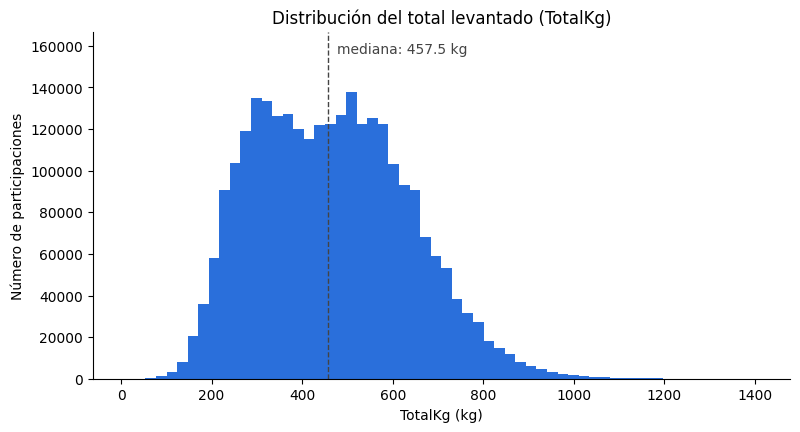

In [ ]:
# --- Gráfico 1: histograma del total levantado (TotalKg) ---
fig, ax = plt.subplots(figsize=(9, 4.5))   # lienzo: 9 pulgadas de ancho x 4,5 de alto

# Histograma: reparte los totales en 60 intervalos y cuenta cuántas filas caen en cada uno
ax.hist(df_sbd["TotalKg"], bins=60, color="#2a6fdb")

# Dejamos un 15 % de espacio libre arriba para poder escribir la etiqueta sin tapar barras
ax.set_ylim(0, ax.get_ylim()[1] * 1.15)

# Línea discontinua en la mediana (el valor que deja la mitad de las filas a cada lado)
mediana = df_sbd["TotalKg"].median()
ax.axvline(mediana, color="#444444", linestyle="--", linewidth=1)
ax.annotate(f"mediana: {mediana:.1f} kg",
            xy=(mediana, ax.get_ylim()[1] * 0.97),      # arriba del todo, sobre las barras
            xytext=(6, 0), textcoords="offset points",   # 6 puntos a la derecha de la línea
            va="top", color="#444444")

ax.set_title("Distribución del total levantado (TotalKg)")
ax.set_xlabel("TotalKg (kg)")
ax.set_ylabel("Número de participaciones")
sns.despine()   # quita las líneas de arriba y de la derecha
plt.show()

**Lectura del histograma:** la mayoría de los totales está entre unos 200 y 700 kg, con una mediana de 457,5 kg. La distribución es asimétrica: tiene una cola larga hacia la derecha (muy pocos totales por encima de 1.000 kg) y varios picos en la parte central, probablemente porque mezcla categorías y sexos muy distintos.

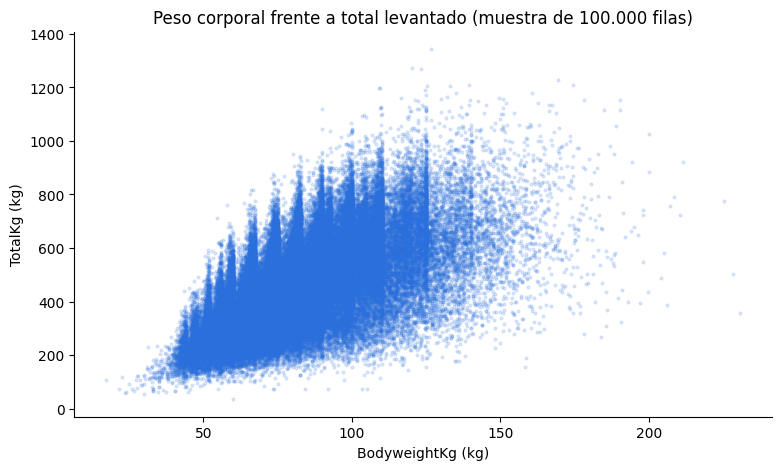

In [ ]:
# --- Gráfico 2: peso corporal frente a total levantado ---
# Con 2,7 millones de puntos el gráfico sería ilegible y tardaría mucho:
# usamos una muestra aleatoria de 100.000 filas (random_state fija la muestra para repetirla)
muestra = df_sbd.sample(n=100_000, random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))

# s=4: puntos pequeños; alpha=0.15: puntos casi transparentes, así donde hay
# muchos juntos se ve más oscuro y se aprecia dónde se concentran
ax.scatter(muestra["BodyweightKg"], muestra["TotalKg"], s=4, alpha=0.15, color="#2a6fdb")

ax.set_title("Peso corporal frente a total levantado (muestra de 100.000 filas)")
ax.set_xlabel("BodyweightKg (kg)")
ax.set_ylabel("TotalKg (kg)")
sns.despine()
plt.show()

In [ ]:
# ¿Hay pesos que se repiten mucho? (si hay franjas, algunos valores concretos aparecerán muy arriba)
df_sbd["BodyweightKg"].round(1).value_counts().head(10)

,count
BodyweightKg,
90.0,41346
75.0,40226
82.5,40092
100.0,34277
67.5,31504
110.0,24768
60.0,22425
56.0,18900
125.0,16324


**Lectura de la dispersión:** el total aumenta con el peso corporal, pero con mucha dispersión: con el mismo peso hay totales muy distintos, así que el peso por sí solo no basta para predecir. Por encima de unos 120 kg la nube deja de subir con claridad.

También se ven franjas verticales. Los pesos más repetidos son 90, 75, 82,5, 100, 67,5, 110, 60, 56, 125 y 52 kg (entre 13.000 y 41.000 filas cada uno), que coinciden con los límites habituales de las categorías de peso. No sabemos si se debe a que muchos levantadores pesan justo el límite o a que algunas federaciones anotan el límite en lugar del peso real.

Comparamos el total levantado entre grupos con diagramas de caja: la caja contiene el 50 % central de las filas, la línea interior es la mediana y los puntos sueltos son valores extremos. Usamos la muestra de 100.000 filas. En el gráfico por sexo dejamos fuera `Mx`, que solo tiene 162 filas en todo el subconjunto.

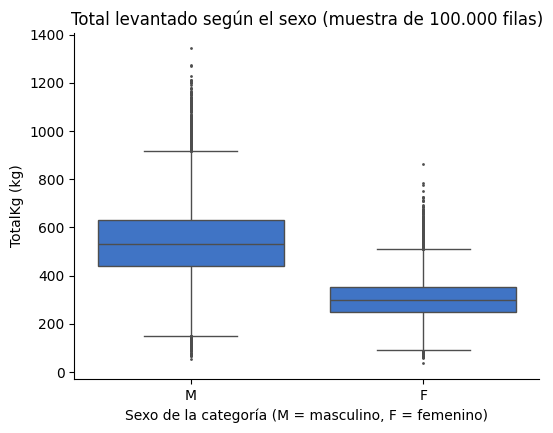

In [ ]:
# --- Gráfico 3: total levantado según el sexo ---
fig, ax = plt.subplots(figsize=(6, 4.5))

# Boxplot: una caja por grupo. Dejamos fuera Mx (solo 162 filas: no se vería nada fiable)
sns.boxplot(data=muestra, x="Sex", y="TotalKg", order=["M", "F"],
            color="#2a6fdb", fliersize=1, ax=ax)   # fliersize: tamaño de los puntos extremos

ax.set_title("Total levantado según el sexo (muestra de 100.000 filas)")
ax.set_xlabel("Sexo de la categoría (M = masculino, F = femenino)")
ax.set_ylabel("TotalKg (kg)")
sns.despine()
plt.show()

**Lectura del gráfico por sexo:** las cajas de `M` y `F` no se solapan: la mediana masculina (unos 530 kg) es bastante mayor que la femenina (unos 300 kg). El sexo es, por tanto, un atributo muy informativo para predecir `TotalKg`. Ambos grupos tienen valores extremos altos.

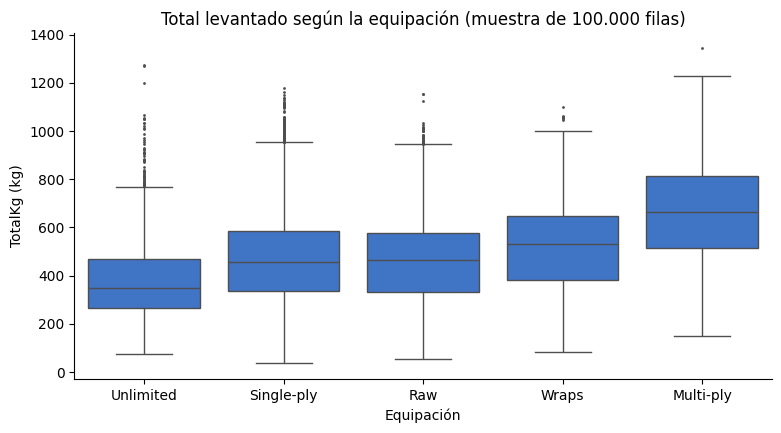

In [ ]:
# --- Gráfico 4: total levantado según la equipación ---
# Ordenamos las cajas de menor a mayor mediana para que se lea mejor
orden = (muestra.groupby("Equipment", observed=True)["TotalKg"]
                .median().sort_values().index)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=muestra, x="Equipment", y="TotalKg", order=orden,
            color="#2a6fdb", fliersize=1, ax=ax)

ax.set_title("Total levantado según la equipación (muestra de 100.000 filas)")
ax.set_xlabel("Equipación")
ax.set_ylabel("TotalKg (kg)")
sns.despine()
plt.show()

In [ ]:
df_sbd["Equipment"].value_counts()

,count
Equipment,
Raw,1153137
Single-ply,1014489
Unlimited,269583
Wraps,227664
Multi-ply,51654
Straps,1


**Lectura del gráfico por equipación:** `Multi-ply` tiene los totales más altos (mediana de unos 665 kg) y `Wraps` le sigue. `Single-ply` y `Raw` son muy parecidas (unos 455-465 kg). `Unlimited` tiene la mediana más baja (unos 350 kg), algo que no esperábamos y cuya causa desconocemos. Las diferencias entre equipaciones pueden estar mezcladas con las de sexo, edad y federación, así que no demuestran que la equipación sea la causa.

Número de filas por equipación: `Raw` 1.153.137, `Single-ply` 1.014.489, `Unlimited` 269.583, `Wraps` 227.664, `Multi-ply` 51.654 y `Straps` solo 1 (por eso no sale en el gráfico).

Para ver de dónde vienen los datos y cómo han cambiado con el tiempo, mostramos las 10 federaciones con más participaciones y la evolución por año del número de participaciones y del total mediano. Hay que tener en cuenta que 2026 no está completo: los datos llegan hasta el 1 de noviembre.

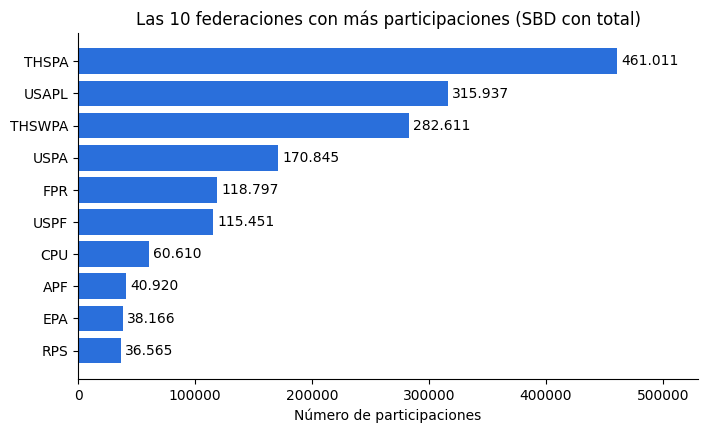

In [ ]:
# --- Gráfico 5: las 10 federaciones con más participaciones ---
top = df_sbd["Federation"].value_counts().head(10)   # cuenta filas por federación

fig, ax = plt.subplots(figsize=(8, 4.5))
# Barras horizontales; invertimos el orden ([::-1]) para que la mayor quede arriba
barras = ax.barh(top.index.astype(str)[::-1], top.values[::-1], color="#2a6fdb")
# Escribimos el número al final de cada barra (con punto como separador de miles)
ax.bar_label(barras, labels=[f"{v:,}".replace(",", ".") for v in top.values[::-1]], padding=3)
ax.set_title("Las 10 federaciones con más participaciones (SBD con total)")
ax.set_xlabel("Número de participaciones")
ax.set_xlim(0, top.values.max() * 1.15)   # hueco a la derecha para los números
sns.despine()
plt.show()

**Lectura del gráfico de federaciones:** los datos están muy concentrados: las tres federaciones con más participaciones (THSPA, USAPL y THSWPA) suman 1.059.559 filas (el 39,0 % del subconjunto) y las diez primeras suman 1.640.913 (el 60,4 %). Como en el conjunto hay 479 federaciones distintas, la mayoría tiene muy pocas filas; en la preparación de datos habrá que agrupar las menos frecuentes.

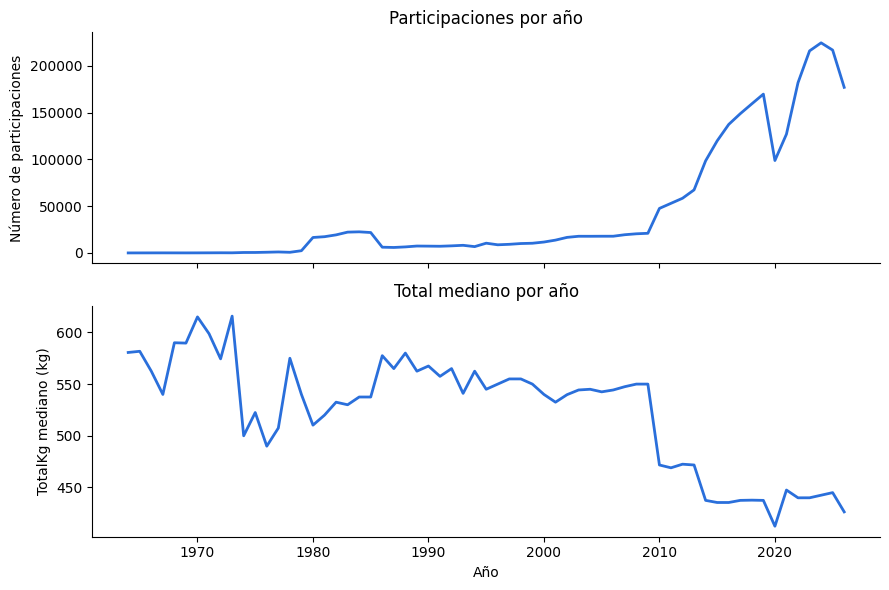

In [ ]:
# --- Gráfico 6: evolución por año ---
anio = df_sbd["Date"].dt.year                     # sacamos el año de la fecha
por_anio = df_sbd.groupby(anio)["TotalKg"].agg(["size", "median"])
# size = nº de filas del año; median = total mediano del año

# Dos gráficos apilados que comparten el eje de años; cada uno con su propio eje Y
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax1.plot(por_anio.index, por_anio["size"], color="#2a6fdb", linewidth=2)
ax1.set_title("Participaciones por año")
ax1.set_ylabel("Número de participaciones")

ax2.plot(por_anio.index, por_anio["median"], color="#2a6fdb", linewidth=2)
ax2.set_title("Total mediano por año")
ax2.set_ylabel("TotalKg mediano (kg)")
ax2.set_xlabel("Año")

sns.despine()
plt.tight_layout()   # separa los gráficos para que no se pisen los textos
plt.show()

**Lectura de la evolución por año:** antes de 2010 hay pocas participaciones por año; a partir de 2010 crecen con fuerza hasta unas 170.000 en 2019, caen en 2020 y alcanzan un máximo de unas 225.000 en 2024. El dato de 2026 está incompleto (llega hasta el 1 de noviembre). El total mediano baja de unos 550 kg a unos 470 kg en 2010 y a unos 437 kg desde 2014. No sabemos la causa; una hipótesis es que al crecer los datos entran más perfiles distintos (por ejemplo, más mujeres o más jóvenes). Las medianas de los primeros años son poco fiables porque se calculan con muy pocas filas. El año de la competición parece un atributo útil.

### 3.5 Correlaciones

Calculamos la correlación de Pearson entre las variables numéricas y `TotalKg`. Va de -1 a 1 y solo mide relaciones lineales. Incluimos a propósito los tres levantamientos para comprobar la fuga de datos. Convertimos el sexo en una variable numérica (`EsHombre`: 1 si `M`, 0 si no; las 162 filas `Mx` cuentan como 0) y sacamos el año de la fecha.

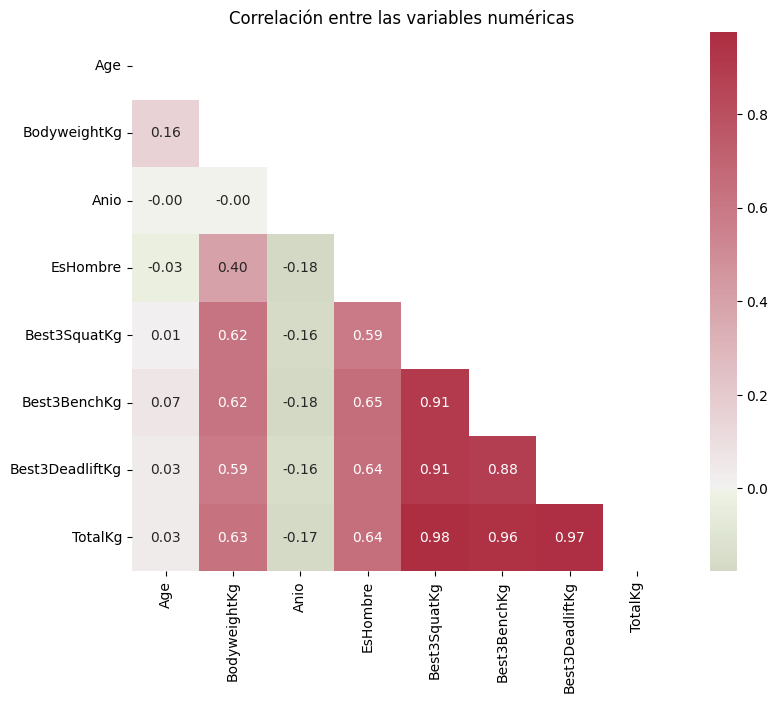

,TotalKg
Best3SquatKg,0.98
Best3DeadliftKg,0.97
Best3BenchKg,0.96
EsHombre,0.64
BodyweightKg,0.63
Age,0.03
Anio,-0.17


In [ ]:
# Tabla solo con columnas numéricas (la correlación de Pearson solo funciona con números)
num = pd.DataFrame({
    "Age": df_sbd["Age"],
    "BodyweightKg": df_sbd["BodyweightKg"],
    "Anio": df_sbd["Date"].dt.year,
    "EsHombre": (df_sbd["Sex"] == "M").astype(int),   # 1 si M, 0 si F o Mx
    "Best3SquatKg": df_sbd["Best3SquatKg"],
    "Best3BenchKg": df_sbd["Best3BenchKg"],
    "Best3DeadliftKg": df_sbd["Best3DeadliftKg"],
    "TotalKg": df_sbd["TotalKg"],
})

corr = num.corr()   # correlación entre cada par; ignora los pares donde falta algún dato

# Máscara que oculta la mitad superior de la matriz (es simétrica: se repite)
mask = np.triu(np.ones_like(corr, dtype=bool))

# Paleta divergente como en clase: dos colores en los extremos y un tono claro en el centro (0)
cmap = sns.diverging_palette(100, 7, s=75, l=40, n=5, center="light", as_cmap=True)

plt.figure(figsize=(10, 7))
# center=0: el color claro corresponde a correlación 0; annot=True: escribe el valor en cada celda
# fmt=".2f": 2 decimales; square=True: celdas cuadradas
sns.heatmap(corr, mask=mask, center=0, annot=True, fmt=".2f", square=True, cmap=cmap)
plt.title("Correlación entre las variables numéricas")
plt.show()

# Correlación de cada variable con TotalKg, de mayor a menor
corr["TotalKg"].drop("TotalKg").sort_values(ascending=False).round(2)

**Lectura de las correlaciones:**
- Los tres levantamientos tienen correlaciones de 0,96-0,98 con `TotalKg`, porque lo componen: confirma que no pueden usarse como atributos (fuga de datos).
- Entre las variables que sí conoceríamos de antemano, las que más se relacionan con el total son el sexo (`EsHombre`, 0,64) y el peso corporal (0,63). Entre ellas se correlacionan (0,40), así que parte de la información se solapa.
- `Anio` tiene una correlación débil y negativa (-0,17), coherente con la bajada del total mediano que vimos en el gráfico por año.
- `Age` casi no tiene correlación lineal (0,03), pero la correlación de Pearson solo detecta relaciones lineales. Comprobamos con un gráfico si la relación tiene otra forma.

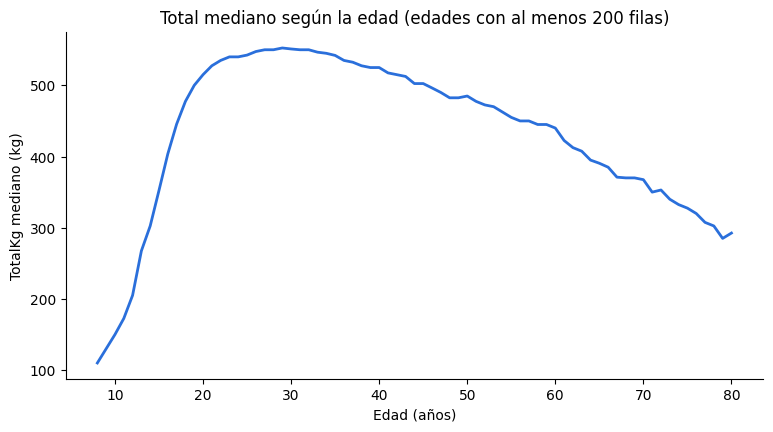

In [ ]:
# --- Gráfico 7: total mediano según la edad ---
# Edad entera: astype(int) recorta los decimales (23,5 pasa a 23)
edad = df_sbd["Age"].dropna().astype(int)

# Para cada edad: cuántas filas hay y cuál es el total mediano
por_edad = df_sbd.loc[edad.index].groupby(edad)["TotalKg"].agg(["size", "median"])

# Nos quedamos con las edades con al menos 200 filas (con menos, la mediana no es fiable)
por_edad = por_edad[por_edad["size"] >= 200]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(por_edad.index, por_edad["median"], color="#2a6fdb", linewidth=2)
ax.set_title("Total mediano según la edad (edades con al menos 200 filas)")
ax.set_xlabel("Edad (años)")
ax.set_ylabel("TotalKg mediano (kg)")
sns.despine()
plt.show()

**Lectura del gráfico por edad:** el total mediano sube muy rápido de los 8 a los 20 años (de unos 110 a unos 520 kg), se mantiene en una meseta de unos 540-550 kg entre los 23 y los 35 años aproximadamente y baja de forma gradual después (unos 485 kg a los 50, unos 370 a los 70 y unos 290-300 kg a los 78-80). La relación tiene forma de U invertida, por eso la correlación lineal con `Age` era casi cero (0,03) aunque la edad sí influye. Cada punto es la mediana de personas distintas, no el seguimiento de una misma persona, y `Age` tiene un 41,5 % de nulos.

### 3.6 ¿Por qué faltan tantas edades?

`Age` tiene un 41,5 % de nulos en el subconjunto. Según el README, la edad es opcional y cada federación aporta los datos que quiere, así que comprobamos si los vacíos se concentran en unas federaciones y cuántas filas podrían recuperarse con `AgeClass` (la franja de edad).

In [ ]:
# % de filas sin Age en cada una de las 10 federaciones con más filas
top10 = df_sbd["Federation"].value_counts().head(10).index
(df_sbd[df_sbd["Federation"].isin(top10)]
   .groupby("Federation", observed=True)["Age"]
   .apply(lambda s: round(s.isna().mean() * 100, 1))
   .sort_values(ascending=False))

,Age
Federation,
THSPA,94.2
THSWPA,93.2
USPF,83.8
CPU,69.3
RPS,46.1
EPA,45.3
APF,20.8
USAPL,7.0
FPR,1.1


In [ ]:
# ¿Cuántas filas sin Age tienen al menos la franja de edad (AgeClass)?
sin_edad = df_sbd["Age"].isna()
print("Filas sin Age:", sin_edad.sum())
print("... pero con AgeClass:", (sin_edad & df_sbd["AgeClass"].notna()).sum())

Filas sin Age: 1126565
... pero con AgeClass: 296536


**Conclusiones del 3.6**

- Los vacíos no son aleatorios: dependen de la federación. THSPA y THSWPA, dos de las tres con más filas, no informan de la edad en el 94,2 % y el 93,2 % de sus filas; USPF, CPU, RPS y EPA tienen entre el 45 % y el 84 % sin edad; USAPL, FPR y USPA casi siempre la dan (7,0 %, 1,1 % y 0,1 %).
- De las 1.126.565 filas sin `Age`, 296.536 sí tienen `AgeClass`; quedan 830.029 filas (30,6 %) sin ninguna de las dos.
- En la preparación de datos tendremos que decidir qué hacer con ellas. Borrarlas dejaría casi sin datos a dos de las tres mayores federaciones, y rellenarlas con la media falsearía la relación con la edad.

### Conclusiones del apartado 3

- **Filas de trabajo:** nos quedamos con `Event` = `SBD` y `TotalKg` con valor: 2.716.528 de las 4.063.068 filas (66,9 %).
- **Fuga de datos:** `TotalKg` es exactamente la suma de los tres levantamientos (correlación de 0,96-0,98), así que `Best3SquatKg`, `Best3BenchKg` y `Best3DeadliftKg` no se usarán como atributos.
- **Atributos con más relación con el total:** el sexo (`M` frente a `F`: cajas que no se solapan) y el peso corporal. La equipación y el año también muestran diferencias, aunque pueden estar mezcladas con el sexo, la edad y la federación.
- **La edad influye, pero no de forma lineal:** sube hasta los 20-30 años y baja después. Tiene un 41,5 % de nulos concentrados en unas federaciones (THSPA y THSWPA casi nunca la informan), que habrá que tratar con cuidado.
- **Problemas para la preparación de datos:** muchos nulos en `Age` (41,5 %); 479 federaciones, con el 60,4 % de las filas en solo 10; `Straps` con 1 fila y `Mx` con 162; `Tested` vacío significa "no"; unos pocos valores raros (por ejemplo, un total de 520 kg con menos de 10 años); y 1.019.033 nombres distintos en 4.063.068 filas (los levantadores se repiten), así que habrá que separar entrenamiento y prueba por levantador.

## 4. Exposición del objetivo

**Objetivo.** Construir un modelo que estime el **total levantado** (`TotalKg`: suma de sentadilla, press de banca y peso muerto) de una persona que participa en una competición de powerlifting completa (`Event` = `SBD`), a partir de datos que se conocen antes de que levante: sexo, peso corporal, edad, equipación, federación, país, si la categoría tiene control antidopaje y año de la competición.

**Target (valor a predecir):** `TotalKg`, en kilogramos. Es un valor numérico continuo, así que es un problema de **regresión**.

**Atributos candidatos:** `Sex`, `BodyweightKg`, `Age` (o `AgeClass`), `Equipment`, `Federation`, `Country`, `Tested` y el año de `Date`.

**Atributos finales (tras la preparación de datos del apartado 5):** `Sex`, `BodyweightKg`, `Age`, `EdadEstimada` (indica si la edad se estimó a partir de `AgeClass`), `Equipment`, `Federation`, `Country`, `Tested` y `Anio` (año de `Date`).

**Columnas que no se usan como atributos:**
- `Best3SquatKg`, `Best3BenchKg` y `Best3DeadliftKg`: `TotalKg` es exactamente su suma (la diferencia es 0 en las 2.704.932 filas que tienen los tres), así que usarlas sería darle la respuesta al modelo (**fuga de datos**).
- `Dots`, `Wilks`, `Glossbrenner` y `Goodlift`: se calculan a partir del total. No se cargaron.
- `Name`: no es un atributo; se usa para repartir entrenamiento y prueba por levantador.

**Cómo mediremos el rendimiento:** con el **RMSE** (error medio en kg) y el **R²** (proporción de la variación del total que explica el modelo), comparados con una línea base que siempre predice la media. Entrenamiento y prueba se reparten **por levantador**, para que una misma persona no aparezca en los dos conjuntos.

**Limitaciones que conocemos desde ya:**
- Solo incluye competiciones `SBD` con un total válido: no hay descalificados ni quienes fallan un levantamiento.
- No tenemos datos de entrenamiento, experiencia ni historial de la persona, que influyen mucho en lo que levanta.
- La edad falta en el 41,5 % de las filas.
- Muchas personas aparecen en varias competiciones, y la composición de los datos cambió a partir de 2010 (más participaciones y total mediano más bajo), así que no está claro que lo aprendido se aplique igual a datos futuros.


## 5. Preparación de los datos para los algoritmos de Machine Learning

Dejamos los datos listos para entrenar en este orden: (1) elegimos columnas y arreglamos los valores vacíos que tienen significado, (2) tratamos la edad, (3) separamos entrenamiento y prueba **por levantador**, y (4) rellenamos, escalamos y codificamos usando **solo el conjunto de entrenamiento**, para que el de prueba no influya en nada de lo que aprende el modelo (evitamos así la fuga de datos).

### 5.1 Selección de columnas y valores vacíos con significado

Nos quedamos con los atributos candidatos del apartado 4, el target (`TotalKg`) y `Name`, que solo se usará para repartir los datos por levantador. Sacamos el año de `Date`. Según el README, `Tested` vacío significa "no" (la categoría no tiene control antidopaje), así que lo rellenamos con `"No"`. En `Country` (2,3 % de nulos) usamos `"Desconocido"`.

In [ ]:
# Tabla de trabajo: solo lo que necesitamos (atributos, target y Name para repartir por levantador)
datos = pd.DataFrame({
    "Name": df_sbd["Name"],
    "Sex": df_sbd["Sex"],
    "Equipment": df_sbd["Equipment"],
    "Age": df_sbd["Age"],
    "AgeClass": df_sbd["AgeClass"],             # la usamos en 5.2 para rescatar edades
    "BodyweightKg": df_sbd["BodyweightKg"],
    "Federation": df_sbd["Federation"],
    "Country": df_sbd["Country"],
    "Tested": df_sbd["Tested"],
    "Anio": df_sbd["Date"].dt.year,             # año de la competición
    "TotalKg": df_sbd["TotalKg"],               # target
})

# Tested vacío significa "No" (README). En una columna category hay que añadir
# primero la categoría nueva y luego rellenar.
datos["Tested"] = datos["Tested"].cat.add_categories("No").fillna("No")

# Country: el vacío no tiene significado; lo marcamos como "Desconocido"
datos["Country"] = datos["Country"].cat.add_categories("Desconocido").fillna("Desconocido")

print(datos.shape)
datos.isna().mean().mul(100).round(1)   # % de nulos que quedan por columna


(2716528, 11)


,0
Name,0.0
Sex,0.0
Equipment,0.0
Age,41.5
AgeClass,30.6
BodyweightKg,0.5
Federation,0.0
Country,0.0
Tested,0.0
Anio,0.0


### 5.2 Edad: rescatar valores con `AgeClass`

`Age` tiene un 41,5 % de nulos. Para 296.536 de esas filas conocemos la franja de edad (`AgeClass`, por ejemplo `40-44`), así que la convertimos en una edad aproximada: el punto medio de la franja (la franja abierta `90-999` usa su límite inferior). Antes de usarla medimos cuánto se equivoca esta aproximación en las filas que tienen a la vez la edad real y la franja, y marcamos las filas rellenadas con la columna `EdadEstimada`. Las 830.029 filas que no tienen ni edad ni franja se tratan más adelante.

In [ ]:
# ¿Qué valores tiene AgeClass y cuántas filas hay en cada uno?
datos["AgeClass"].value_counts(dropna=False)

,count
AgeClass,
NaN,830031
24-34,519960
20-23,352582
18-19,310413
16-17,225484
35-39,118013
40-44,101463
45-49,65232
13-15,62360


In [ ]:
# Convertimos cada franja ("40-44") en dos números: límite inferior y superior
limites = datos["AgeClass"].astype(str).str.split("-", expand=True)
inferior = pd.to_numeric(limites[0], errors="coerce")   # los vacíos ("nan") quedan como NaN
superior = pd.to_numeric(limites[1], errors="coerce")

# Edad aproximada = punto medio de la franja
punto_medio = (inferior + superior) / 2
# La franja "90-999" es abierta: usamos su límite inferior (90)
punto_medio = punto_medio.where(superior != 999, inferior)

# ¿Cuánto se equivoca esta aproximación? Lo medimos donde conocemos la edad real y la franja
ambas = datos["Age"].notna() & punto_medio.notna()
error = (datos.loc[ambas, "Age"] - punto_medio[ambas]).abs()
print("Filas con edad real y franja:", ambas.sum())
print("Error medio de la aproximación (años):", error.mean().round(2))

# Marcamos las filas cuya edad vamos a rellenar con la franja y la rellenamos
datos["EdadEstimada"] = (datos["Age"].isna() & punto_medio.notna()).astype(int)
datos["Age"] = datos["Age"].fillna(punto_medio)

# AgeClass ya no hace falta
datos = datos.drop(columns="AgeClass")

print("Filas con edad estimada:", datos["EdadEstimada"].sum())
print("Filas que siguen sin edad:", datos["Age"].isna().sum(),
      f"({datos['Age'].isna().mean() * 100:.1f} %)")

Filas con edad real y franja: 1589961
Error medio de la aproximación (años): 1.55
Filas con edad estimada: 296536
Filas que siguen sin edad: 830029 (30.6 %)


**Resultado del 5.2**

- Medida sobre las 1.589.961 filas que tienen a la vez la edad real y la franja, la aproximación por punto medio se equivoca de media 1,55 años.
- Rescatamos 296.536 filas, que quedan marcadas con `EdadEstimada` = 1. Siguen sin edad 830.029 filas (30,6 %); se tratan en el apartado 5.4 (rellenar con la mediana y añadir un indicador de edad desconocida) en el apartado 6 se mide el error de esas filas, pero no se ha comparado con quitarlas.
- Limitación: el error se midió en filas de federaciones que informan de las dos columnas; en las rescatadas puede ser distinto.

### 5.3 Separación en entrenamiento y prueba

Reservamos un 20 % de los levantadores para la prueba. Repartimos **por levantador** (`Name`) y no por filas, porque una misma persona aparece en muchas competiciones: si algunas de sus filas estuvieran en entrenamiento y otras en prueba, el modelo se evaluaría con gente que ya conoce y la nota sería mejor de lo real. Fijamos `random_state` para que el reparto se pueda repetir.

In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# Cada levantador tiene un código numérico (cat.codes): así la separación es más rápida
grupos = datos["Name"].cat.codes

# n_splits=1: un solo reparto; test_size=0.2: el 20 % de los levantadores va a la prueba
divisor = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
idx_train, idx_test = next(divisor.split(datos, groups=grupos))

train = datos.iloc[idx_train]
test = datos.iloc[idx_test]

print("Filas de entrenamiento:", len(train), "| filas de prueba:", len(test))
print(f"% de filas en prueba: {len(test) / len(datos) * 100:.1f}")

# Comprobación: ¿hay algún levantador en los dos conjuntos? (debe dar 0)
comunes = np.intersect1d(train["Name"].cat.codes.unique(), test["Name"].cat.codes.unique())
print("Levantadores en ambos conjuntos:", len(comunes))

# ¿Se parece el target en los dos conjuntos?
pd.DataFrame({"train": train["TotalKg"].describe(), "test": test["TotalKg"].describe()}).round(1)

Filas de entrenamiento: 2171449 | filas de prueba: 545079
% de filas en prueba: 20.1
Levantadores en ambos conjuntos: 0


,train,test
count,2171449.0,545079.0
mean,465.1,465.4
std,168.1,168.3
min,7.0,7.0
25%,328.8,328.8
50%,457.5,457.5
75%,582.9,582.5
max,1407.5,1372.1


**Resultado del 5.3**

- Entrenamiento: 2.171.449 filas; prueba: 545.079 (20,1 %; no es exactamente el 20 % porque se reparten levantadores y no filas).
- Ningún levantador aparece en los dos conjuntos.
- El target tiene una distribución casi idéntica en ambos (media 465,1 kg en entrenamiento y 465,4 kg en prueba; mediana 457,5 kg en los dos), así que la prueba es representativa.

### 5.4 Rellenar, escalar y codificar

Montamos el preprocesado con `ColumnTransformer` y lo **ajustamos solo con el conjunto de entrenamiento**; después lo aplicamos igual al de prueba:
- **Atributos numéricos** (`Age`, `BodyweightKg`, `Anio`, `EdadEstimada`): rellenamos los vacíos con la mediana de entrenamiento, añadimos una columna que indica si el valor estaba vacío (para no perder esa información) y escalamos.
- **Atributos categóricos** (`Sex`, `Equipment`, `Federation`, `Country`, `Tested`): *one-hot* (una columna de 0/1 por categoría). Las categorías con menos de 1.000 filas de entrenamiento se agrupan como "poco frecuentes"; así controlamos las 479 federaciones y casos como `Straps` (1 fila) o `Mx` (162 filas).

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

atributos_num = ["Age", "BodyweightKg", "Anio", "EdadEstimada"]
atributos_cat = ["Sex", "Equipment", "Federation", "Country", "Tested"]

# Atributos (X) y target (y) de cada conjunto
X_train = train[atributos_num + atributos_cat]
y_train = train["TotalKg"]
X_test = test[atributos_num + atributos_cat]
y_test = test["TotalKg"]

# Números: 1) rellenar con la mediana y añadir un indicador de "estaba vacío"; 2) escalar
tuberia_num = Pipeline([
    ("imputar", SimpleImputer(strategy="median", add_indicator=True)),
    ("escalar", StandardScaler()),
])

# Categorías: una columna 0/1 por categoría; las que tienen < 1000 filas se agrupan como "poco frecuentes";
# handle_unknown: si en prueba aparece una categoría que no vimos, no da error
tuberia_cat = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=1000)

preprocesado = ColumnTransformer([
    ("num", tuberia_num, atributos_num),
    ("cat", tuberia_cat, atributos_cat),
])

# fit: aprende (medianas, medias, categorías) SOLO con entrenamiento
preprocesado.fit(X_train)

# transform: aplica lo aprendido a los dos conjuntos
X_train_prep = preprocesado.transform(X_train)
X_test_prep = preprocesado.transform(X_test)
print("Entrenamiento:", X_train_prep.shape, "| Prueba:", X_test_prep.shape)

# ¿Cuántas categorías de cada atributo, y cuántas se agruparon como poco frecuentes?
codificador = preprocesado.named_transformers_["cat"]
for nombre, cats, raras in zip(atributos_cat, codificador.categories_, codificador.infrequent_categories_):
    print(nombre, "->", len(cats), "categorías;", 0 if raras is None else len(raras), "agrupadas como poco frecuentes")

# Mediana con la que se rellenó Age (calculada con entrenamiento)
print("Mediana de Age:", preprocesado.named_transformers_["num"]["imputar"].statistics_[0].round(1))

Entrenamiento: (2171449, 233) | Prueba: (545079, 233)
Sex -> 3 categorías; 1 agrupadas como poco frecuentes
Equipment -> 6 categorías; 1 agrupadas como poco frecuentes
Federation -> 441 categorías; 290 agrupadas como poco frecuentes
Country -> 175 categorías; 112 agrupadas como poco frecuentes
Tested -> 2 categorías; 0 agrupadas como poco frecuentes
Mediana de Age: 23.0


**Resultado del 5.4**

- El preprocesado deja 233 columnas en entrenamiento (2.171.449 filas) y en prueba (545.079 filas): 6 numéricas (4 atributos más 2 indicadores de "valor vacío", para `Age` y `BodyweightKg`) y 227 de las categorías codificadas.
- De las 441 federaciones de entrenamiento, 151 tienen columna propia y las otras 290 (menos de 1.000 filas cada una) se agrupan como "poco frecuentes"; igual con 112 de los 175 países, `Straps` (1 fila) y `Mx` (162 filas).
- La mediana usada para rellenar `Age` es 23 años, calculada solo con el conjunto de entrenamiento.
- Limitación: rellenar con la mediana hace que las 830.029 filas sin edad parezcan tener todas 23 años. El indicador de edad vacía lo compensa en parte; no se ha comparado con quitar esas filas (queda como limitación).

### 5.5 Guardar los datos preparados

Guardamos en Drive los conjuntos de entrenamiento y de prueba (en formato Parquet, que es compacto y conserva los tipos de las columnas) y el preprocesado ya ajustado. Así el apartado 6 puede empezar desde aquí sin repetir todo el proceso.

In [ ]:
import joblib
import os

# Carpeta nueva dentro de proyecto_ml (si ya existe, no da error)
carpeta = "/content/drive/MyDrive/proyecto_ml/datos_preparados"
os.makedirs(carpeta, exist_ok=True)

# Parquet: formato columnar y comprimido; mantiene los tipos (category, float...)
train.to_parquet(f"{carpeta}/train.parquet")
test.to_parquet(f"{carpeta}/test.parquet")

# El preprocesado ya ajustado con entrenamiento (medianas, medias, categorías)
joblib.dump(preprocesado, f"{carpeta}/preprocesado.joblib")

# Tamaño de cada fichero guardado, en MB
for fichero in os.listdir(carpeta):
    print(fichero, round(os.path.getsize(f"{carpeta}/{fichero}") / 1e6, 1), "MB")

train.parquet 50.5 MB
test.parquet 15.2 MB
preprocesado.joblib 0.0 MB
resultados_modelos.csv 0.0 MB


**Resultado del 5.5**

Se guardan tres ficheros en la carpeta `datos_preparados` de Drive: `train.parquet` (50,5 MB), `test.parquet` (15,2 MB) y `preprocesado.joblib` (menos de 0,1 MB). El apartado 6 puede cargarlos directamente. (En la salida también aparece `resultados_modelos.csv`, que se crea en el apartado 6.)

### Conclusiones del apartado 5

- **Tabla de trabajo:** 2.716.528 filas con 9 atributos (`Sex`, `Equipment`, `Age`, `EdadEstimada`, `BodyweightKg`, `Federation`, `Country`, `Tested`, `Anio`), el target `TotalKg` y `Name` para el reparto.
- **Valores vacíos con significado:** `Tested` vacío se interpreta como "No" (README) y `Country` vacío como "Desconocido".
- **Edad:** rescatamos 296.536 filas con la franja `AgeClass` (error medio de 1,55 años medido donde se conocen las dos); siguen sin edad 830.029 filas (30,6 %), que se rellenan con la mediana de entrenamiento (23 años) y llevan un indicador de "edad vacía".
- **Reparto:** por levantador, 80 % / 20 % (2.171.449 filas de entrenamiento y 545.079 de prueba, sin ningún levantador en ambos). El target tiene casi la misma distribución en los dos.
- **Preprocesado ajustado solo con entrenamiento:** relleno, escalado y *one-hot* (las categorías con menos de 1.000 filas se agrupan como "poco frecuentes"): 233 columnas.

## 6. Entrenamiento del modelo y comprobación del rendimiento

Entrenamos varios modelos con el conjunto de entrenamiento y medimos su error en entrenamiento y en prueba (con los datos de prueba, que el modelo no ha visto, se mide el rendimiento real). Usamos dos medidas:
- **RMSE:** error típico de la predicción, en kg (cuanto menor, mejor).
- **R²:** proporción de la variación del total que explica el modelo (1 es perfecto; 0 es igual que predecir siempre la media).

Para saber si un modelo aporta algo, siempre lo comparamos con la **línea base**: predecir para todos la media del total de entrenamiento.


### Cargar los datos preparados

Esta celda carga los datos preparados del apartado 5.5 (si Colab se ha reiniciado, o se empieza directamente en el apartado 6, es lo que los recupera) y define las funciones que usamos en este apartado. Se ejecuta siempre al empezar el apartado 6.

In [ ]:
# Ejecutar siempre al empezar el apartado 6: carga los datos preparados (del 5.5) y define las funciones.
# Si se ejecuta desde otra cuenta, cambiar la ruta por la de la carpeta compartida.
import os
import pandas as pd, numpy as np, joblib
from google.colab import drive
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import root_mean_squared_error, r2_score
drive.mount('/content/drive')

carpeta = "/content/drive/MyDrive/proyecto_ml/datos_preparados"
train = pd.read_parquet(f"{carpeta}/train.parquet")
test = pd.read_parquet(f"{carpeta}/test.parquet")
preprocesado = joblib.load(f"{carpeta}/preprocesado.joblib")

atributos_num = ["Age", "BodyweightKg", "Anio", "EdadEstimada"]
atributos_cat = ["Sex", "Equipment", "Federation", "Country", "Tested"]
X_train, y_train = train[atributos_num + atributos_cat], train["TotalKg"]
X_test, y_test = test[atributos_num + atributos_cat], test["TotalKg"]
X_train_prep = preprocesado.transform(X_train)
X_test_prep = preprocesado.transform(X_test)

# Muestra de 200.000 filas (la misma de antes: misma semilla)
idx = np.random.RandomState(42).choice(X_train_prep.shape[0], size=200_000, replace=False)
X_muestra = X_train_prep[idx]
y_muestra = y_train.iloc[idx]

# Tabla de resultados: se guarda en Drive cada vez que se evalúa un modelo, para no perderla
ruta_resultados = f"{carpeta}/resultados_modelos.csv"
if os.path.exists(ruta_resultados):
    resultados = pd.read_csv(ruta_resultados).to_dict("records")
else:
    # Recuperados de las ejecuciones anteriores (antes del reinicio de Colab)
    resultados = [
        {"modelo": "Línea base (media)", "RMSE entrenamiento": 168.105, "RMSE prueba": 168.270, "R² entrenamiento": 0.000, "R² prueba": 0.000},
        {"modelo": "Regresión lineal", "RMSE entrenamiento": 96.245, "RMSE prueba": 96.037, "R² entrenamiento": 0.672, "R² prueba": 0.674},
        {"modelo": "Árbol sin límite (muestra)", "RMSE entrenamiento": 28.626, "RMSE prueba": 111.428, "R² entrenamiento": 0.971, "R² prueba": 0.561},
        {"modelo": "Árbol limitado (muestra)", "RMSE entrenamiento": 84.351, "RMSE prueba": 86.018, "R² entrenamiento": 0.748, "R² prueba": 0.739},
        {"modelo": "Random forest (muestra)", "RMSE entrenamiento": 81.383, "RMSE prueba": 83.041, "R² entrenamiento": 0.766, "R² prueba": 0.756},
        {"modelo": "Gradient boosting (muestra)", "RMSE entrenamiento": 77.249, "RMSE prueba": 80.168, "R² entrenamiento": 0.789, "R² prueba": 0.773},
    ]
    pd.DataFrame(resultados).to_csv(ruta_resultados, index=False)

def evaluar(nombre, modelo, X_tr=None, y_tr=None):
    """Entrena el modelo y mide RMSE y R² en entrenamiento y en prueba."""
    if X_tr is None:
        X_tr, y_tr = X_train_prep, y_train
    modelo.fit(X_tr, y_tr)
    pred_train = modelo.predict(X_tr)
    pred_test = modelo.predict(X_test_prep)   # la prueba es siempre completa
    fila = {
        "modelo": nombre,
        "RMSE entrenamiento": root_mean_squared_error(y_tr, pred_train),
        "RMSE prueba": root_mean_squared_error(y_test, pred_test),
        "R² entrenamiento": r2_score(y_tr, pred_train),
        "R² prueba": r2_score(y_test, pred_test),
    }
    resultados[:] = [r for r in resultados if r["modelo"] != nombre]   # si el modelo ya estaba, lo sustituimos
    resultados.append(fila)
    pd.DataFrame(resultados).to_csv(ruta_resultados, index=False)   # copia de seguridad en Drive
    return pd.DataFrame([fila]).set_index("modelo").round(3)

# Gradient boosting que acepta matrices dispersas (las convierte a densas al predecir)
class HGBDenso(HistGradientBoostingRegressor):
    def predict(self, X):
        return super().predict(X.toarray() if hasattr(X, "toarray") else X)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

### 6.1 Línea base

Un modelo que predice siempre la media del total de entrenamiento. Es el mínimo que debe superar cualquier modelo.

In [ ]:
# Línea base: predice siempre la media del total de entrenamiento
evaluar("Línea base (media)", DummyRegressor(strategy="mean"))

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Línea base (media),168.105,168.27,0.0,-0.0


### 6.2 Regresión lineal

El modelo más sencillo: el total se calcula como una suma de los atributos (ya escalados y codificados) multiplicados cada uno por un peso que aprende el modelo. No puede captar relaciones con forma de curva, como la edad en U invertida, así que esperamos que mejore la línea base pero se quede corto.

In [ ]:
# Regresión lineal: ajusta una recta (un plano, con varios atributos) a los datos
evaluar("Regresión lineal", LinearRegression())

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Regresión lineal,96.245,96.037,0.672,0.674


**Resultado del 6.1 y 6.2**

- La línea base tiene un RMSE de 168,3 kg en prueba y un R² de 0: es la desviación del total, y es lo que hay que batir.
- La regresión lineal baja el RMSE a 96,0 kg en prueba (un 43 % menos) y explica el 67,4 % de la variación (R² = 0,674).
- El error en entrenamiento (96,2 kg) y en prueba (96,0 kg) es prácticamente el mismo: no hay sobreajuste, y el resultado confirma que la separación por levantador es honesta. El modelo se queda corto porque una relación lineal no capta efectos como la forma de U de la edad.

### 6.3 Árbol de decisión

Un árbol hace una serie de preguntas sobre los atributos (por ejemplo, "¿es hombre?", "¿pesa más de 90 kg?") y predice el total medio del grupo al que llega cada persona. Capta relaciones que no son rectas, como la edad en U invertida. Su riesgo es el sobreajuste: si crece sin límite, se aprende los datos de entrenamiento de memoria. Lo comprobamos entrenando un árbol sin límite y otro limitado (máximo 12 niveles y al menos 50 filas por hoja). Por rapidez entrenamos con una muestra aleatoria de 200.000 filas; la evaluación se hace siempre sobre toda la prueba.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

# Muestra aleatoria de 200.000 filas de entrenamiento (rápido de entrenar)
rng = np.random.RandomState(42)
idx = rng.choice(X_train_prep.shape[0], size=200_000, replace=False)
X_muestra = X_train_prep[idx]
y_muestra = y_train.iloc[idx]

In [ ]:
# Árbol sin límite de profundidad: crece hasta aprenderse cada fila
evaluar("Árbol sin límite (muestra)", DecisionTreeRegressor(random_state=42), X_muestra, y_muestra)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Árbol sin límite (muestra),28.626,111.428,0.971,0.561


In [ ]:
# Árbol limitado: máximo 12 niveles y al menos 50 filas por hoja
evaluar("Árbol limitado (muestra)",
        DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=42),
        X_muestra, y_muestra)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Árbol limitado (muestra),84.351,86.018,0.748,0.739


**Resultado del 6.3**

- El árbol sin límite se aprende los datos de entrenamiento (R² 0,971, RMSE 28,6 kg) pero generaliza mal (R² 0,561, RMSE 111,4 kg en prueba): es un caso claro de sobreajuste, y queda peor que la regresión lineal.
- Limitando su tamaño (12 niveles y al menos 50 filas por hoja) el resultado mejora: RMSE de 86,0 kg en prueba (frente a 96,0 kg de la regresión lineal) y R² de 0,739, con un error casi igual en entrenamiento (84,4 kg), es decir, sin sobreajuste apreciable.
- Los árboles captan relaciones que una recta no (como la edad en U invertida). Se entrenaron con una muestra de 200.000 filas de entrenamiento.

### 6.4 Random forest

Un random forest entrena muchos árboles, cada uno con una parte distinta de las filas y de los atributos, y promedia sus predicciones. Como cada árbol se equivoca en cosas distintas, al promediar los errores se compensan y el sobreajuste baja. Lo entrenamos con la misma muestra de 200.000 filas y lo evaluamos sobre toda la prueba.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

bosque = RandomForestRegressor(
    n_estimators=60,        # número de árboles
    min_samples_leaf=20,    # mínimo de filas por hoja (evita árboles que memorizan)
    max_features=0.3,       # cada división mira solo el 30 % de los atributos (más rápido y más variado)
    max_samples=0.5,        # cada árbol se entrena con el 50 % de las filas de la muestra
    n_jobs=-1,              # usa todos los núcleos disponibles
    random_state=42,
)
evaluar("Random forest (muestra)", bosque, X_muestra, y_muestra)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Random forest (muestra),81.383,83.041,0.766,0.756


**Resultado del 6.4**

- El random forest mejora al árbol limitado: RMSE de 83,0 kg en prueba (frente a 86,0 kg) y R² de 0,756 (frente a 0,739), con un error casi igual en entrenamiento (81,4 kg), sin sobreajuste apreciable.
- Respecto a la línea base (RMSE 168,3 kg) el error baja un 51 %, y respecto a la regresión lineal (96,0 kg), un 13,5 %.
- Las mejoras entre modelos son cada vez menores, lo que sugiere que parte del error no se debe al modelo sino a la información que falta (por ejemplo, el entrenamiento o la experiencia del levantador). Se entrenó con una muestra de 200.000 filas.

### 6.5 Gradient boosting

El gradient boosting entrena árboles pequeños uno detrás de otro, de modo que cada uno corrige los errores de los anteriores. Usamos `HistGradientBoostingRegressor` de scikit-learn, que es rápido con muchos datos. Necesita la matriz en formato denso, así que la convertimos. Primero lo entrenamos con la misma muestra de 200.000 filas (para compararlo con los demás en igualdad de condiciones) y después con 1 millón de filas, para ver si más datos ayudan. No usamos las 2,17 millones de filas de entrenamiento porque, al pasarlas a formato denso, probablemente no caben en la memoria de Colab (el intento reinició el entorno).

In [ ]:
# Este modelo necesita una matriz densa: convertimos la muestra (unos 370 MB)
X_muestra_densa = X_muestra.toarray()

evaluar("Gradient boosting (muestra)",
        HGBDenso(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=42),
        X_muestra_densa, y_muestra)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Gradient boosting (muestra),77.249,80.168,0.789,0.773


In [ ]:
# 1 millón de filas de entrenamiento en formato denso (~1,9 GB)
idx_1m = np.random.RandomState(42).choice(X_train_prep.shape[0], size=1_000_000, replace=False)
X_1m = X_train_prep[idx_1m].toarray()
y_1m = y_train.iloc[idx_1m]

evaluar("Gradient boosting (1 millón de filas)",
        HGBDenso(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=42),
        X_1m, y_1m)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Gradient boosting (1 millón de filas),78.835,79.635,0.78,0.776


**Resultado del 6.5 (1 millón de filas)**

- Con 1 millón de filas el gradient boosting obtiene un RMSE de 79,6 kg en prueba y un R² de 0,776, frente a 80,2 kg y 0,773 con 200.000 filas: multiplicar los datos por cinco apenas mejora el error (0,5 kg), aunque sí reduce la diferencia entre entrenamiento y prueba (de 2,9 a 0,8 kg).
- Esto sugiere que el límite no está en la cantidad de datos sino en la información que aportan los atributos: no conocemos el entrenamiento ni la experiencia de cada levantador.
- Es el mejor modelo: reduce el error un 53 % respecto a la línea base y un 17 % respecto a la regresión lineal.

In [ ]:
pd.DataFrame(resultados).set_index("modelo").round(3)

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Línea base (media),168.105,168.270,0.000,-0.000
Regresión lineal,96.245,96.037,0.672,0.674
Árbol sin límite (muestra),28.626,111.428,0.971,0.561
Árbol limitado (muestra),84.351,86.018,0.748,0.739
Random forest (muestra),81.383,83.041,0.766,0.756
Gradient boosting (muestra),77.249,80.168,0.789,0.773
Gradient boosting (1 millón de filas),78.835,79.635,0.780,0.776


### 6.6 Validación cruzada agrupada

Hasta aquí hemos comparado los modelos mirando el resultado en la prueba. Es más limpio **elegir el modelo con validación cruzada dentro del entrenamiento** y usar la prueba una sola vez, al final, para medir el modelo elegido.

La validación cruzada reparte el entrenamiento en 3 partes, entrena con 2 y valida con la restante, repite cambiando la parte de validación y promedia el error. Lo hacemos **por levantador** (`GroupKFold`), como en el reparto entre entrenamiento y prueba, para que una misma persona no esté a la vez en la parte de entrenamiento y en la de validación. Por rapidez usamos la muestra de 200.000 filas de entrenamiento; ninguna fila de la prueba interviene. Comparamos los cuatro tipos de modelo con los mismos hiperparámetros de los apartados anteriores.

In [ ]:
from sklearn.model_selection import GroupKFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Matriz densa de la muestra (la del 6.5; si Colab se ha reiniciado, se vuelve a crear)
X_cv = X_muestra_densa if "X_muestra_densa" in globals() else X_muestra.toarray()

# Código de levantador de cada fila de la muestra: GroupKFold reparte por levantador, no por filas
grupos_muestra = pd.factorize(train["Name"].iloc[idx])[0]
cv = GroupKFold(n_splits=3)

# Los cuatro modelos, con los mismos hiperparámetros que en los apartados 6.2 a 6.5
modelos_cv = {
    "Regresión lineal": LinearRegression(),
    "Árbol limitado": DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=42),
    "Random forest": RandomForestRegressor(n_estimators=60, min_samples_leaf=20, max_features=0.3,
                                           max_samples=0.5, n_jobs=-1, random_state=42),
    "Gradient boosting": HGBDenso(max_iter=300, learning_rate=0.1, max_leaf_nodes=63, random_state=42),
}

filas_cv = []
for nombre, modelo in modelos_cv.items():
    # Entrena y valida 3 veces; scoring: RMSE (sklearn lo da en negativo) y R²
    res = cross_validate(modelo, X_cv, y_muestra, cv=cv, groups=grupos_muestra,
                         scoring={"rmse": "neg_root_mean_squared_error", "r2": "r2"})
    filas_cv.append({
        "modelo": nombre,
        "RMSE CV (kg)": -res["test_rmse"].mean(),
        "desviación del RMSE": res["test_rmse"].std(),
        "R² CV": res["test_r2"].mean(),
        "segundos por partición": res["fit_time"].mean(),
    })

tabla_cv = pd.DataFrame(filas_cv).set_index("modelo").sort_values("RMSE CV (kg)")
tabla_cv.round(3)

,RMSE CV (kg),desviación del RMSE,R² CV,segundos por partición
modelo,,,,
Gradient boosting,80.791,0.081,0.769,66.995
Random forest,83.914,0.168,0.751,29.153
Árbol limitado,86.551,0.150,0.735,3.981
Regresión lineal,96.241,0.261,0.672,10.224


**Resultado del 6.6.** Validación cruzada agrupada por levantador (3 partes, sobre la muestra de 200.000 filas de entrenamiento):
- **Gradient boosting:** RMSE 80,79 kg (desviación entre partes 0,08) y R² 0,769.
- **Random forest:** RMSE 83,91 kg (desviación 0,17) y R² 0,751.
- **Árbol limitado:** RMSE 86,55 kg (desviación 0,15) y R² 0,735.
- **Regresión lineal:** RMSE 96,24 kg (desviación 0,26) y R² 0,672.

El orden de los modelos es el mismo que vimos al compararlos en la prueba. Las desviaciones entre partes (de 0,08 a 0,26 kg) son mucho menores que las diferencias entre modelos (de varios kg), así que la ventaja del gradient boosting no depende de cómo se reparta la muestra. Por eso lo elegimos como modelo final.

### 6.7 Ajuste de hiperparámetros

Un **hiperparámetro** se fija antes de entrenar y controla cómo aprende el modelo. Ajustamos los del gradient boosting con `GridSearchCV`, que prueba todas las combinaciones de una rejilla pequeña y se queda con la de menor RMSE en validación cruzada (la misma validación agrupada del 6.6, sobre la misma muestra de 200.000 filas de entrenamiento, sin tocar la prueba). Probamos el número máximo de hojas de cada árbol (`max_leaf_nodes`: más hojas, árboles más complejos) y la tasa de aprendizaje (`learning_rate`: cuánto corrige cada árbol a los anteriores). Es una búsqueda corta, no exhaustiva.

In [ ]:
from sklearn.model_selection import GridSearchCV

rejilla = {
    "max_leaf_nodes": [31, 63, 127],
    "learning_rate": [0.05, 0.1],
}

busqueda = GridSearchCV(
    HGBDenso(max_iter=300, random_state=42),
    param_grid=rejilla,
    cv=cv,                                   # la misma validación cruzada agrupada del 6.6
    scoring="neg_root_mean_squared_error",
    n_jobs=1,                                # el propio gradient boosting ya usa varios núcleos
)
busqueda.fit(X_cv, y_muestra, groups=grupos_muestra)

print("Mejores hiperparámetros:", busqueda.best_params_)
print("RMSE de validación cruzada con ellos:", round(-busqueda.best_score_, 2), "kg")

# Todas las combinaciones, de menor a mayor RMSE
tabla_rejilla = pd.DataFrame(busqueda.cv_results_)[["param_max_leaf_nodes", "param_learning_rate", "mean_test_score"]]
tabla_rejilla["RMSE CV (kg)"] = -tabla_rejilla.pop("mean_test_score")
tabla_rejilla.sort_values("RMSE CV (kg)").round(2)

Mejores hiperparámetros: {'learning_rate': 0.05, 'max_leaf_nodes': 127}
RMSE de validación cruzada con ellos: 80.76 kg


,param_max_leaf_nodes,param_learning_rate,RMSE CV (kg)
2,127,0.05,80.76
4,63,0.10,80.79
5,127,0.10,80.86
1,63,0.05,80.89
3,31,0.10,80.97
0,31,0.05,81.31


**Resultado del 6.7.** La búsqueda probó 6 combinaciones (3 valores de `max_leaf_nodes` por 2 de `learning_rate`) y la mejor fue `learning_rate=0.05` con `max_leaf_nodes=127`, con un RMSE de validación cruzada de 80,76 kg. Las seis combinaciones quedan entre 80,76 y 81,31 kg, y la configuración que usábamos antes (63 hojas, 0,1) da 80,79 kg. Es decir, ajustar los hiperparámetros apenas mejora el resultado: el modelo es poco sensible a estos dos valores dentro de este rango. Una limitación: la mejor combinación está en el borde de la rejilla (el valor más alto de hojas y el más bajo de `learning_rate`), así que podría existir una configuración algo mejor fuera de ella; no se ha probado.

### 6.8 Modelo final y evaluación en la prueba

Entrenamos el gradient boosting con los mejores hiperparámetros del 6.7, esta vez con 1 millón de filas de entrenamiento, y lo medimos **una sola vez** en la prueba. Así la prueba no ha intervenido en ninguna elección de modelo ni de hiperparámetros. Guardamos el modelo en Drive para no tener que entrenarlo otra vez si Colab se reinicia.

In [ ]:
# 1 millón de filas densas (las del 6.5; si Colab se ha reiniciado, se vuelven a crear)
if "X_1m" not in globals():
    idx_1m = np.random.RandomState(42).choice(X_train_prep.shape[0], size=1_000_000, replace=False)
    X_1m = X_train_prep[idx_1m].toarray()
    y_1m = y_train.iloc[idx_1m]

mejores = busqueda.best_params_                      # los elegidos por validación cruzada en el 6.7
modelo_final = HGBDenso(max_iter=300, random_state=42, **mejores)
resultado_final = evaluar("Gradient boosting ajustado (1 millón de filas)", modelo_final, X_1m, y_1m)
joblib.dump(modelo_final, f"{carpeta}/modelo_final_cv.joblib")   # copia en Drive
resultado_final

,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Gradient boosting ajustado (1 millón de filas),78.618,79.493,0.781,0.777


**Resultado del 6.8.** El modelo final (gradient boosting con los mejores hiperparámetros, entrenado con 1 millón de filas) da en la prueba un RMSE de 79,49 kg y un R² de 0,777; en entrenamiento, 78,62 kg y 0,781. La diferencia entre entrenamiento y prueba es de 0,9 kg, así que no hay sobreajuste importante. Frente a predecir la media (168,27 kg) el error baja un 53 %, y frente a la regresión lineal (96,04 kg), un 17 %. Mejora solo 0,14 kg respecto al modelo sin ajustar (79,64 kg). La prueba se ha usado para evaluar el modelo final, pero hay que reconocer que ya habíamos visto en ella los resultados de los modelos de 6.1 a 6.5 antes de hacer la validación cruzada; el orden que dio la validación cruzada coincide con ese, por lo que la elección no cambia.

In [ ]:
# Tabla comparativa de todos los modelos evaluados en la prueba
# (los resultados se guardaron en Drive cada vez que se evaluó un modelo)
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

ruta_resultados = "/content/drive/MyDrive/proyecto_ml/datos_preparados/resultados_modelos.csv"
pd.read_csv(ruta_resultados).set_index("modelo").round(3)

Mounted at /content/drive


,RMSE entrenamiento,RMSE prueba,R² entrenamiento,R² prueba
modelo,,,,
Línea base (media),168.105,168.270,0.000,-0.000
Regresión lineal,96.245,96.037,0.672,0.674
Árbol sin límite (muestra),28.626,111.428,0.971,0.561
Árbol limitado (muestra),84.351,86.018,0.748,0.739
Random forest (muestra),81.383,83.041,0.766,0.756
Gradient boosting (muestra),77.249,80.168,0.789,0.773
Gradient boosting (1 millón de filas),78.835,79.635,0.780,0.776
Gradient boosting ajustado (1 millón de filas),78.618,79.493,0.781,0.777


### 6.9 Análisis de errores del modelo final

El RMSE es un promedio, así que miramos si el error es parecido en todos los grupos o si el modelo falla más en unos que en otros. Usamos el modelo final del apartado 6.8 (el gradient boosting con los hiperparámetros elegidos por validación cruzada, entrenado con 1 millón de filas). Calculamos el error de cada predicción en prueba (predicción menos valor real: positivo si el modelo se pasa, negativo si se queda corto).

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# El modelo final se entrena y se guarda en el apartado 6.8. Si Colab se ha reiniciado
# y la variable ya no existe, lo cargamos de Drive (necesita HGBDenso, de la celda de recuperación).
if "modelo_final" not in globals():
    modelo_final = joblib.load(f"{carpeta}/modelo_final_cv.joblib")

# Predicciones sobre la prueba y error de cada una
analisis = test[atributos_num + atributos_cat].copy()
analisis["real"] = y_test.values
analisis["prediccion"] = modelo_final.predict(X_test_prep)
analisis["error"] = analisis["prediccion"] - analisis["real"]    # positivo: se pasa; negativo: se queda corto

# Grupos de edad (las filas sin edad forman su propio grupo)
grupo = pd.cut(analisis["Age"], [0, 13, 18, 23, 35, 50, 65, 120])
analisis["grupo_edad"] = grupo.cat.add_categories("sin edad").fillna("sin edad")

def error_por_grupo(columna):
    """Filas, RMSE (kg) y error medio (sesgo) de cada grupo."""
    return (analisis.groupby(columna, observed=True)["error"]
            .agg(filas="size",
                 RMSE=lambda e: np.sqrt((e ** 2).mean()),
                 sesgo="mean")
            .round(1))

print("Por sexo:");       display(error_por_grupo("Sex"))
print("Por equipación:"); display(error_por_grupo("Equipment"))
print("Por edad:");       display(error_por_grupo("grupo_edad"))

Por sexo:


,filas,RMSE,sesgo
Sex,,,
F,169311,59.0,0.6
M,375735,87.2,-0.4
Mx,33,115.8,-21.1


Por equipación:


,filas,RMSE,sesgo
Equipment,,,
Multi-ply,10710,116.5,-0.3
Raw,231579,74.6,-0.5
Single-ply,203795,82.4,0.3
Unlimited,53229,74.9,-0.3
Wraps,45766,84.7,0.6


Por edad:


,filas,RMSE,sesgo
grupo_edad,,,
"(0, 13]",2885,58.1,2.4
"(13, 18]",72932,70.1,-0.5
"(18, 23]",114260,74.8,0.0
"(23, 35]",107477,84.4,-0.2
"(35, 50]",56323,86.2,-0.2
"(50, 65]",20275,77.0,0.4
"(65, 120]",4223,67.8,-1.7
sin edad,166704,81.7,0.1


**Resultado del 6.9**

- El error es parecido en todos los grupos grandes y el sesgo es casi nulo (como máximo ±2,4 kg, en el grupo de 0 a 13 años): el modelo no se pasa ni se queda corto de forma sistemática.
- El error en kg es mayor donde los totales son mayores: hombres (RMSE 87,2 kg frente a 59,0 kg en mujeres), `Multi-ply` (116,5 kg) y edades de 23 a 50 años (entre 84 y 86 kg). Es esperable que crezca con el total.
- Es menor en niños (58,1 kg hasta los 13 años) y en mayores de 65 años (67,8 kg).
- Las filas sin edad (30,6 % de la prueba) tienen un RMSE de 81,7 kg, unos 3 kg más que las que sí la tienen (unos 78,5 kg, calculado a partir de las tablas), así que mantenerlas con la edad rellenada no empeora mucho el modelo. No hemos probado a entrenar sin ellas.
- `Mx` tiene solo 33 filas en la prueba; no se puede sacar ninguna conclusión de su error.

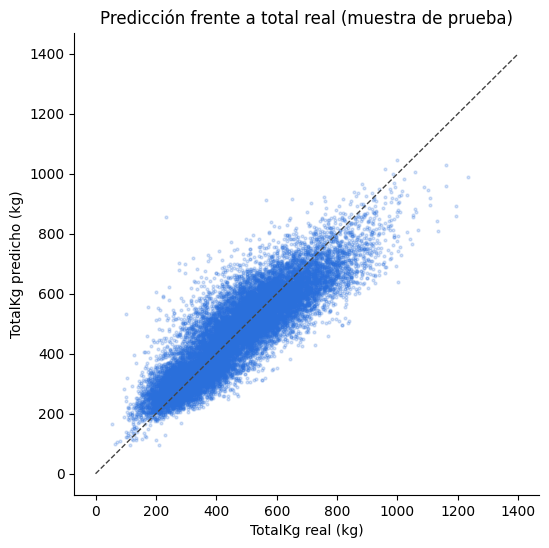

In [ ]:
# Predicción frente a realidad (muestra de 20.000 filas de prueba)
m = analisis.sample(20_000, random_state=42)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(m["real"], m["prediccion"], s=4, alpha=0.2, color="#2a6fdb")
ax.plot([0, 1400], [0, 1400], color="#444444", linestyle="--", linewidth=1)   # predicción perfecta
ax.set_title("Predicción frente a total real (muestra de prueba)")
ax.set_xlabel("TotalKg real (kg)")
ax.set_ylabel("TotalKg predicho (kg)")
sns.despine()
plt.show()

**Resultado: predicción frente a realidad**

- Los puntos siguen la diagonal: el modelo acierta la tendencia general, y quien más levanta recibe en general una predicción más alta.
- La nube es ancha (para un total real de unos 600 kg, las predicciones van aproximadamente de 400 a 800 kg), coherente con un RMSE de unos 80 kg.
- La nube es más plana que la diagonal: con totales bajos el modelo tiende a predecir de más y con totales muy altos, de menos. Es decir, acerca sus predicciones a la media y le cuesta llegar a los extremos. Esto no contradice el sesgo casi nulo del 6.9, que se calculó por grupos de sexo, equipación y edad, no por total real.
- Hipótesis (no comprobada): con solo 9 atributos el modelo no sabe cuánta fuerza tiene cada persona dentro de su grupo, así que predice lo típico para ese perfil.

### 6.10 Importancia de los atributos

Para saber en qué atributos se apoya el modelo usamos la importancia por permutación: desordenamos al azar los valores de un atributo en una muestra de 50.000 filas de prueba y medimos cuánto empeora el RMSE (se repite 3 veces y se promedia). Cuanto más empeora, más depende el modelo de ese atributo.

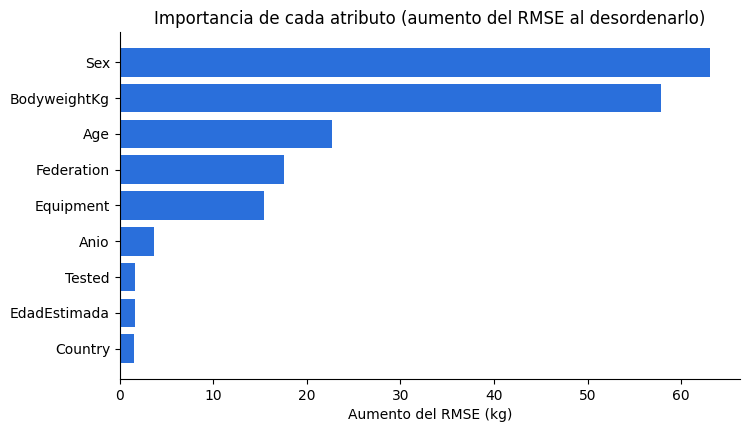

RMSE de referencia en esta muestra: 79.4 kg


,0
Sex,63.1
BodyweightKg,57.9
Age,22.6
Federation,17.5
Equipment,15.4
Anio,3.6
Tested,1.7
EdadEstimada,1.6
Country,1.6


In [ ]:
# Muestra de 50.000 filas de prueba (con las columnas originales, antes del preprocesado)
sub = test.sample(50_000, random_state=42)
X_sub = sub[atributos_num + atributos_cat].reset_index(drop=True)
y_sub = sub["TotalKg"].values

# Error de referencia, sin desordenar nada
rmse_base = root_mean_squared_error(y_sub, modelo_final.predict(preprocesado.transform(X_sub)))

rng = np.random.RandomState(0)
importancia = {}
for col in atributos_num + atributos_cat:
    X_perm = X_sub.copy()
    errores = []
    for _ in range(3):                                   # 3 repeticiones para que no dependa del azar
        X_perm[col] = rng.permutation(X_sub[col].values)  # desordenamos solo esta columna
        pred = modelo_final.predict(preprocesado.transform(X_perm))
        errores.append(root_mean_squared_error(y_sub, pred))
    importancia[col] = np.mean(errores) - rmse_base       # cuánto sube el error (kg)

importancia = pd.Series(importancia).sort_values()        # de menor a mayor para el gráfico

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importancia.index, importancia.values, color="#2a6fdb")
ax.set_title("Importancia de cada atributo (aumento del RMSE al desordenarlo)")
ax.set_xlabel("Aumento del RMSE (kg)")
sns.despine()
plt.show()

print("RMSE de referencia en esta muestra:", round(rmse_base, 1), "kg")
importancia.sort_values(ascending=False).round(1)

**Resultado del 6.10**

- El RMSE de referencia en esta muestra de 50.000 filas es de 79,4 kg (en las 545.079 filas de prueba era 79,5 kg).
- Los atributos que más pesan son `Sex` (el error sube 63,1 kg al desordenarlo) y `BodyweightKg` (57,9 kg). Es coherente con lo visto en el apartado 3: los hombres levantan más que las mujeres y el total crece con el peso corporal.
- Les siguen `Age` (22,6 kg), `Federation` (17,5 kg) y `Equipment` (15,4 kg).
- `Anio` aporta algo (3,6 kg), y `Tested`, `Country` y `EdadEstimada` casi nada (entre 1,6 y 1,7 kg).
- Esta importancia mide cuánto empeora este modelo concreto sin cada atributo, no si el atributo "causa" el total. Además, no son sumables entre sí: si dos atributos están relacionados (como `Country` y `Federation`), desordenar uno puede quedar compensado por el otro.
- `EdadEstimada` vale 1 solo en las filas cuya edad se rellenó con la franja `AgeClass` (296.536 de 2.716.528). Su aporte es casi nulo (1,6 kg), pero eso no prueba que rellenar la edad fuera la mejor opción; no lo hemos comparado con otra.

### 6.11 Predicciones de ejemplo

Para ver cómo se usa el modelo con datos nuevos, elegimos al azar cinco levantadores del conjunto de prueba (que el modelo no vio al entrenar). Pasamos sus datos por el mismo preprocesado y comparamos la predicción con el total que levantaron de verdad. Son solo cinco casos, así que sirven de ejemplo y no de medida del rendimiento: eso lo dan el RMSE y el R² de los apartados anteriores.

In [ ]:
# Cinco levantadores reales de la prueba (el modelo no los vio al entrenar)
ejemplos = test.sample(5, random_state=7).copy()
ejemplos["TotalKg predicho"] = modelo_final.predict(preprocesado.transform(ejemplos[atributos_num + atributos_cat]))
ejemplos["Error (kg)"] = ejemplos["TotalKg predicho"] - ejemplos["TotalKg"]
ejemplos[["Sex", "Age", "BodyweightKg", "Equipment", "TotalKg", "TotalKg predicho", "Error (kg)"]].round(1)

,Sex,Age,BodyweightKg,Equipment,TotalKg,TotalKg predicho,Error (kg)
3535213,M,30.0,94.6,Raw,500.0,595.7,95.7
14915,F,22.5,101.5,Raw,405.0,368.1,-36.9
1716143,M,NaN,119.2,Single-ply,696.3,532.9,-163.4
3392459,M,34.0,74.2,Single-ply,757.5,597.3,-160.2
2142771,F,31.5,55.8,Single-ply,397.5,316.2,-81.3


**Resultado del 6.11 (levantadores reales de la prueba)**

- El error en estos cinco casos va de -163,4 a +95,7 kg. Son muy pocos para estimar el rendimiento (eso lo dan el RMSE y el R² anteriores).
- Los dos mayores errores corresponden a totales altos (696,3 y 757,5 kg), en los que el modelo predice de menos (-163,4 y -160,2 kg). Encaja con lo visto en el gráfico de predicción frente a realidad, aunque cinco casos no lo demuestran.
- Uno de los levantadores no tiene edad registrada; el modelo usa la edad rellenada en el apartado 5.

In [ ]:
# Cuatro levantadores ficticios (una fila por levantador, con las 9 columnas de entrada)
federacion = train["Federation"].value_counts().index[0]   # la federación más frecuente
pais = train["Country"].value_counts().index[0]            # el país más frecuente

ejemplos = pd.DataFrame({
    "Age":          [25.0, 25.0, 25.0, 55.0],
    "BodyweightKg": [60.0, 83.0, 83.0, 83.0],
    "Anio":         [2024, 2024, 2024, 2024],
    "EdadEstimada": [0, 0, 0, 0],                  # 0 = edad real (1 solo se usa cuando se rellenó con AgeClass)
    "Sex":          ["F", "M", "M", "M"],
    "Equipment":    ["Raw", "Raw", "Single-ply", "Raw"],
    "Federation":   [federacion] * 4,
    "Country":      [pais] * 4,
    "Tested":       ["No"] * 4,
})

# Mismo preprocesado que en el entrenamiento y predicción del modelo final
ejemplos["TotalKg predicho"] = modelo_final.predict(preprocesado.transform(ejemplos[atributos_num + atributos_cat]))
ejemplos[["Sex", "Age", "BodyweightKg", "Equipment", "TotalKg predicho"]].round(1)

,Sex,Age,BodyweightKg,Equipment,TotalKg predicho
0,F,25.0,60.0,Raw,309.2
1,M,25.0,83.0,Raw,454.0
2,M,25.0,83.0,Single-ply,487.8
3,M,55.0,83.0,Raw,442.5


**Resultado del 6.11 (levantadores ficticios)**

- Un hombre de 83 kg predice más que una mujer de 60 kg (454,0 frente a 309,2 kg con `Raw` y 25 años; coherente con la exploración del sexo), y a los 55 años se predice unos 11,5 kg menos que a los 25. La dirección es coherente con la curva de la edad del apartado 3, aunque allí la bajada era mayor porque iba mezclada con otras variables.
- Con el mismo sexo, peso y edad, `Single-ply` predice unos 34 kg más que `Raw`. En la exploración (3.4) las medianas de las dos eran parecidas, pero allí iban mezcladas con otras variables; el modelo, al comparar perfiles iguales, sí encuentra diferencia.
- Al ser levantadores inventados no hay valor real con el que compararlos: esto comprueba que el modelo responde de forma razonable, no que acierte.

## 7. Conclusiones

### Qué hemos hecho
Hemos construido un modelo que **predice el total levantado (`TotalKg`) en competiciones de powerlifting completas (sentadilla, press de banca y peso muerto)** a partir de 9 atributos del levantador y la competición: sexo, edad, peso corporal, equipación, federación, país, año, si la competición tiene control antidopaje y un indicador de si la edad estaba estimada. Se partió de 2.716.528 participaciones del dataset OpenPowerlifting. Se excluyeron como atributos las marcas de cada levantamiento y las puntuaciones calculadas con el total (Dots, Wilks, etc.), porque contienen la respuesta (el total es exactamente la suma de los tres levantamientos). La prueba se separó **por levantador** (ninguno aparece en entrenamiento y prueba), y el preprocesado se ajustó solo con el entrenamiento. Para comparar los modelos usamos además **validación cruzada agrupada por levantador** y ajustamos los hiperparámetros del mejor con una búsqueda en rejilla.

### Resultados
Medimos el error medio (RMSE, en kg) y el R² en el conjunto de prueba:
- Línea base (predecir siempre la media): RMSE 168,3 kg, R² 0,00.
- Regresión lineal: RMSE 96,0 kg, R² 0,674.
- Árbol de decisión limitado: RMSE 86,0 kg, R² 0,739.
- Random forest: RMSE 83,0 kg, R² 0,756.
- Gradient boosting (200.000 filas): RMSE 80,2 kg, R² 0,773.
- **Gradient boosting ajustado (1 millón de filas, modelo final): RMSE 79,5 kg, R² 0,777.**

La validación cruzada (RMSE: gradient boosting 80,8 kg, random forest 83,9, árbol limitado 86,6, regresión lineal 96,2) da el mismo orden que la prueba, con diferencias entre particiones (de 0,08 a 0,26 kg) mucho menores que las diferencias entre modelos. Ajustar los hiperparámetros apenas mejoró el resultado (0,03 kg en validación cruzada y 0,14 kg en la prueba).

El modelo final reduce el error un 53 % respecto a la línea base y un 17 % respecto a la regresión lineal. El árbol sin límite de profundidad es un ejemplo de sobreajuste: R² de 0,971 en entrenamiento y 0,561 en prueba. Pasar de 200.000 a 1 millón de filas mejoró solo unos 0,5 kg el RMSE; hipótesis (no comprobada): el límite está más en la información de los atributos que en la cantidad de datos.

### Qué predice bien y qué no
- Los atributos que más pesan son el sexo (+63,1 kg de error al desordenarlo) y el peso corporal (+57,9 kg), seguidos de la edad, la federación y la equipación. País, control antidopaje y el indicador de edad estimada aportan casi nada.
- El sesgo es casi nulo por sexo, equipación y grupo de edad (como máximo ±2,4 kg, salvo `Mx`, con solo 33 filas en la prueba). El error en kg es mayor donde los totales son mayores (hombres, `Multi-ply`, edades de 23 a 50 años).
- El modelo tiende a acercar sus predicciones a la media: con totales bajos predice de más y con totales muy altos, de menos. Hipótesis (no comprobada): con solo 9 atributos no sabe cuánta fuerza tiene cada persona dentro de su grupo.
- Las predicciones de ejemplo responden de forma razonable (más total en hombres que en mujeres, menos a los 55 que a los 25 años, y unos 34 kg más con `Single-ply` que con `Raw` para el mismo perfil), aunque con errores individuales de hasta unos 160 kg en los cinco casos reales vistos.

### Limitaciones
- Solo se usan 9 atributos y ninguno describe al levantador individualmente (por ejemplo, su historial). Un error de unos 80 kg es mucho para decidir nada sobre una persona concreta.
- El 30,6 % de las filas no tenía edad ni categoría de edad y se rellenó con la mediana. No hemos comparado esto con quitar esas filas.
- La búsqueda de hiperparámetros fue corta (6 combinaciones), con 3 particiones y sobre una muestra de 200.000 filas por el tiempo de cálculo. La mejor combinación quedó en el borde de la rejilla, así que podría haber alguna algo mejor fuera de ella; no se ha probado.
- Los resultados en la prueba de los modelos de 6.1 a 6.5 los vimos antes de hacer la validación cruzada. El orden coincide con el de la validación cruzada, pero la prueba no estuvo "sin mirar" hasta el modelo final.
- El modelo final se entrenó con 1 millón de filas de los 2,17 millones disponibles porque el intento de convertirlas a formato denso reinició el entorno de Colab (probablemente por falta de memoria).
- Solo se incluyen participaciones con un total válido en competiciones completas: no sirve para predecir qué ocurre con quien descalifican o no completa.
- Los datos están sesgados hacia unas pocas federaciones (las 3 primeras suman el 39 % de las filas) y el total mediano baja de forma clara a lo largo de los años; no sabemos la causa.

### Qué se podría hacer con más tiempo
- Añadir atributos individuales, como el mejor total de competiciones anteriores del mismo levantador (con cuidado de usar solo competiciones previas para no filtrar la respuesta).
- Ampliar la búsqueda de hiperparámetros (más combinaciones, más particiones y más filas) y separar un conjunto de validación propio, dejando la prueba solo para la medida final.
- Comparar entrenar con y sin las filas sin edad, y entrenar con todas las filas con más memoria.
